# Рынок автомобилей Казахстана и позиция «Меркур Авто»

**Автор:** Задорожний Илья Владимирович, группа M26-555  
**Дисциплина:** предподготовка и анализ данных  
**Исходные данные:** `autokz2019.csv`, январь — сентябрь 2019 года

Автодилерский холдинг изучает положение «Меркур Авто» на рынке Казахстана. В исходной выгрузке
смешаны разные форматы чисел, варианты названий, пропуски и ошибочные характеристики автомобилей.
Такие различия могут менять группировку продаж и итоговые показатели.

Техническая цель — очистить данные и сохранить CSV, пригодный для дальнейшего анализа и BI.
Аналитическая цель — описать рынок и сравнить объем, стоимость и структуру продаж «Меркур Авто»
с показателями всей выборки. Все преобразования и расчеты находятся в этой тетради.

Порядок работы: загрузка и первичная проверка, очистка и преобразование типов,
исследовательский анализ, сравнение «Меркур Авто» с рынком, общий вывод и выгрузка результата.

Для воспроизведения нужны Python, pandas, NumPy, Matplotlib и Jupyter.
Положите CSV рядом с тетрадью и выполните ячейки сверху вниз.
Последняя ячейка создаст `autokz2019_clean.csv`. Исходный файл сохраняется.

## 1. Загрузка и первичная проверка

В файле разделитель столбцов — `;`, а десятичный разделитель — запятая. Поэтому задаем `sep=';'`
и `decimal=','`. Текстовые числовые поля с единицами измерения обработаем отдельно.
Исходную таблицу оставляем в `raw_data`, чтобы проверять каждое исправление.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 60)
pd.set_option('display.float_format', lambda value: f'{value:,.2f}'.replace(',', ' '))
plt.rcParams.update({'figure.figsize': (12, 7), 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.2})

data_path = next((path for path in [Path('autokz2019.csv'), Path('/datasets/autokz2019.csv')]
                  if path.exists()), None)
if data_path is None:
    raise FileNotFoundError('Положите autokz2019.csv рядом с тетрадью')
raw_data = pd.read_csv(data_path, sep=';', decimal=',', low_memory=False)
print(f'Размер исходной таблицы: {raw_data.shape[0]} строк, {raw_data.shape[1]} столбцов')
print(f'Версии: pandas {pd.__version__}, NumPy {np.__version__}')
display(raw_data.head())
raw_data.info()

Размер исходной таблицы: 39966 строк, 25 столбцов
Версии: pandas 3.0.0, NumPy 2.4.2


,Год,Месяц,Компания,Бренд,Модель,Модификация,Год выпуска,Страна-производитель,Вид топлива,"Объём двиг, л,",Коробка передач,Тип привода,Сегмент,Регион,Наименование дилерского центра,Тип клиента,Форма расчета,Количество,"Цена, USD","Продажа, USD",Область,Сегментация 2013,Класс 2013,Сегментация Eng,Локализация производства
0,2019,Май,Mercur Auto,Audi,A3,TFSI,2018,Германия,Бензин,"1,4",S-tronic,передний,Легковые автомобили Premium,Алматы,Mercur Auto Алматы,Физ. Лицо,безналичный,1.00,28 115.00,28 115.00,г.Алматы,Легковые автомобили,C класс,C,Импорт
1,2019,Август,Mercur Auto,Audi,A3,TFSI,2018,Германия,Бензин,"1,4",S-tronic,передний,Легковые автомобили Premium,Алматы,Mercur Auto Алматы,Юр. Лицо,наличный,1.00,32 246.99,32 246.99,г.Алматы,Легковые автомобили,C класс,C,Импорт
2,2019,Апрель,Mercur Auto,Audi,A4,TFSI,2018,Германия,Бензин,"1,4",S-Tronic,FWD,Легковые автомобили Premium,Алматы,Mercur Auto Алматы,Физ. Лицо,безналичный,1.00,32 000.00,32 000.00,г.Алматы,Легковые автомобили,D класс,D,Импорт
3,2019,Июль,Mercur Auto,Audi,A4,TFSI,2018,Германия,Бензин,"1,4",S-tronic,передний,Легковые автомобили Premium,Алматы,Mercur Auto Алматы,Юр. Лицо,безналичный,1.00,31 929.00,31 929.00,г.Алматы,Легковые автомобили,D класс,D,Импорт
4,2019,Июль,Mercur Auto,Audi,A4,TFSI,2018,Германия,Бензин,"1,4",S-tronic,передний,Легковые автомобили Premium,Алматы,Mercur Auto Алматы,Физ. Лицо,наличный,1.00,31 929.00,31 929.00,г.Алматы,Легковые автомобили,D класс,D,Импорт


<class 'pandas.DataFrame'>
RangeIndex: 39966 entries, 0 to 39965
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Год                             39966 non-null  int64  
 1   Месяц                           39966 non-null  str    
 2   Компания                        39966 non-null  str    
 3   Бренд                           39966 non-null  str    
 4   Модель                          39966 non-null  str    
 5   Модификация                     36375 non-null  str    
 6   Год выпуска                     39465 non-null  str    
 7   Страна-производитель            39966 non-null  str    
 8   Вид топлива                     36826 non-null  str    
 9   Объём двиг, л,                  35708 non-null  str    
 10  Коробка передач                 36711 non-null  str    
 11  Тип привода                     35677 non-null  str    
 12  Сегмент                         33205 non-n

In [2]:
initial_profile = pd.DataFrame({
    'Тип': raw_data.dtypes.astype(str),
    'Пропуски': raw_data.isna().sum(),
    'Пропуски, %': raw_data.isna().mean().mul(100),
    'Уникальные значения': raw_data.nunique(),
})
display(initial_profile)
print('Полностью пустые строки:', raw_data.isna().all(axis=1).sum())
print('Полные повторы строк:', raw_data.duplicated().sum())
display(raw_data[['Количество', 'Цена, USD', 'Продажа, USD']].describe())

,Тип,Пропуски,"Пропуски, %",Уникальные значения
Год,int64,0,0.00,1
Месяц,str,0,0.00,9
Компания,str,0,0.00,40
Бренд,str,0,0.00,46
Модель,str,0,0.00,273
Модификация,str,3591,8.99,1383
Год выпуска,str,501,1.25,9
Страна-производитель,str,0,0.00,19
Вид топлива,str,3140,7.86,10
"Объём двиг, л,",str,4258,10.65,114


Полностью пустые строки: 0
Полные повторы строк: 18698


,Количество,"Цена, USD","Продажа, USD"
count,39 960.00,39 966.00,39 966.00
mean,1.35,28 250.16,33 757.67
std,2.37,20 005.76,50 702.45
min,-1.00,7 100.00,-35 588.25
25%,1.00,15 518.50,16 601.93
50%,1.00,24 282.27,26 248.96
75%,1.00,32 505.66,35 000.00
max,115.00,328 510.97,3 778 206.26


В исходной таблице **39 966 строк и 25 столбцов**. Одна строка может описывать как один автомобиль,
так и партию. Поэтому число строк не равно объему продаж. Есть 18 698 полных повторов, а полностью
пустых строк нет. В шести строках отсутствует количество, хотя цена заполнена и итоговая сумма равна нулю.

Самый большой объем пропусков у формы расчета: этот столбец не нужен для поставленных сравнений.
Пропуски года выпуска и характеристик автомобиля не означают отсутствие продажи.
Их не заполняем средними значениями или наиболее частой категорией.

### Правила обработки

| Проверка | Решение | Почему |
|---|---|---|
| Полные повторы | Удаляем совпадения по всем 25 исходным полям | Так требует задание; без идентификатора сделки это допущение, которое отдельно проверим |
| Ненужные поля | Удаляем дилера, форму расчета, старый сегмент, сегмент Eng, локализацию, тип клиента и модификацию | Для анализа используем компанию и сегментацию 2013; полезные сведения о гибридах и дилерах извлечем до удаления |
| Неявные дубликаты | Убираем лишние пробелы и объединяем подтвержденные варианты названий | Разные написания одного названия не должны создавать разные группы |
| Количество −1 | Сохраняем возврат | Итоговая стоимость тоже отрицательная и равна цене с учетом количества |
| Крупные партии | Сохраняем | Продажа 100 Skoda или 115 Lada не является ошибкой только из-за размера партии |
| Неизвестное количество | Сохраняем пропуск и исключаем строку из KPI | Нулевая сумма не доказывает, что было продано ноль автомобилей |
| Дата | Последний календарный день месяца | В данных известен только месяц, это дата отчетного периода, а не точная дата сделки |
| Неизвестные характеристики | Оставляем пропуски | Иначе распределения топлива, коробок и двигателей будут отражать наши догадки |

Полные повторы проверяем **до удаления столбцов и нормализации**. После этих действий разные исходные
записи могут выглядеть одинаково. Их повторно не удаляем: в удаленных полях могли различаться клиент,
комплектация или дилер. `source_row` хранит номер исходной строки CSV с учетом заголовка.

## 2. Очистка и преобразование данных

### 2.1. Справочники и вспомогательные функции

Названия столбцов переводим на английский. Коды стран соответствуют ISO ALPHA-3;
в частности, Германия — `DEU`, Великобритания — `GBR`, Казахстан — `KAZ`.
Справочник проверен по [таблице Статистического отдела ООН](https://unstats.un.org/unsd/methodology/m49/overview/).
Значение «Корея» трактуем как Южную Корею (`KOR`): в выгрузке это автомобили Hyundai.
Если при повторной загрузке появится неизвестная страна, код попросит дополнить справочник.

In [3]:
COLUMN_NAMES = {
    "Год": "year", "Месяц": "month", "Компания": "company",
    "Бренд": "brand", "Модель": "model", "Модификация": "modification",
    "Год выпуска": "production_year", "Страна-производитель": "country",
    "Вид топлива": "fuel_type", "Объ\u0451м двиг, л,": "engine_volume_l",
    "Коробка передач": "transmission", "Тип привода": "drive_type",
    "Сегмент": "segment_raw", "Регион": "region",
    "Наименование дилерского центра": "dealer", "Тип клиента": "client_type",
    "Форма расчета": "payment_type", "Количество": "quantity",
    "Цена, USD": "unit_price_usd", "Продажа, USD": "total_price_usd",
    "Область": "area", "Сегментация 2013": "segment_2013",
    "Класс 2013": "class_2013", "Сегментация Eng": "segment_eng",
    "Локализация производства": "localization",
}

DROP_COLUMNS = [
    "dealer", "payment_type", "segment_raw", "segment_eng",
    "localization", "client_type", "modification",
]

COUNTRIES = {
    "республика казахстан": "KAZ", "российская федерация": "RUS",
    "япония": "JPN", "турция": "TUR", "таиланд": "THA", "сша": "USA",
    "германия": "DEU", "uk": "GBR", "китай": "CHN", "узбекистан": "UZB",
    "австрия": "AUT", "швеция": "SWE", "корея": "KOR",
    "нидерланды": "NLD", "испания": "ESP", "польша": "POL",
    "бельгия": "BEL", "венгрия": "HUN", "белоруссия": "BLR",
}

COMPANIES = {
    "mercur auto": "Меркур Авто", "mercur autos": "Меркур Авто",
    "меркур авто": "Меркур Авто",
    "ravon motors kazakstan": "Равон Моторс Казахстан",
    "равон моторс казахстан": "Равон Моторс Казахстан",
    "autokapital": "Автокапитал", "автокапитал": "Автокапитал",
    "caspian motors": "Каспиан Моторс", "каспиан моторс": "Каспиан Моторс",
    "mmc rus": "ММС Рус", "ммс рус": "ММС Рус",
    "hino motors": "Хино Моторс Казахстан",
    "хино моторс казахстан": "Хино Моторс Казахстан",
}

MONTHS = dict(zip(
    ["январь", "февраль", "март", "апрель", "май", "июнь", "июль",
     "август", "сентябрь", "октябрь", "ноябрь", "декабрь"],
    range(1, 13),
))

CATEGORY_COLUMNS = ["fuel_type", "transmission", "drive_type", "segment_2013", "class_2013"]

In [4]:
def log_change(audit, step, count, reason):
    audit.append({"Действие": step, "Количество": int(count), "Обоснование": reason})


def number(series):
    text = (series.astype("string").str.replace("\u00a0", "", regex=False)
            .str.replace("\u202f", "", regex=False).str.replace(r"\s+", "", regex=True))
    return pd.to_numeric(text.str.replace(",", ".", regex=False), errors="coerce")

### 2.2. Пустые строки, повторы и текстовые форматы

Функции разбивают очистку на последовательные этапы. В `audit` записываем количество исправлений
и их причины. Неразрывные пробелы в значениях вроде `2 019` удаляются при переводе в число.

In [5]:
def prepare_rows(raw, audit, remove_duplicates=True):
    missing = set(COLUMN_NAMES) - set(raw.columns)
    if missing:
        raise ValueError(f"Нет обязательных столбцов: {sorted(missing)}")
    data = raw.copy()
    empty = data.replace(r"^\s*$", np.nan, regex=True).isna().all(axis=1)
    log_change(audit, "Удалены полностью пустые строки", empty.sum(), "В них нет наблюдений")
    data = data.loc[~empty].copy()
    duplicates = data.duplicated()
    log_change(audit, "Удалены полные повторы исходных строк",
               duplicates.sum() if remove_duplicates else 0,
               "Основной сценарий по заданию; проверка до удаления столбцов")
    if remove_duplicates:
        data = data.loc[~duplicates].copy()
    # Номер строки позволяет вернуться к исходной записи
    data.insert(0, "source_row", data.index + 2)
    data = data.rename(columns=COLUMN_NAMES)
    for column in data.select_dtypes(include=["object", "string"]):
        data[column] = (
            data[column].astype("string").str.replace("\u0451", "е", regex=False)
            .str.replace(r"\s+", " ", regex=True).str.strip()
            .replace({"": pd.NA, "#Н/Д": pd.NA})
        )
    return data

In [6]:
audit = []
data = prepare_rows(raw_data, audit)
print('Строк после удаления полных повторов:', len(data))
display(pd.DataFrame(audit))

Строк после удаления полных повторов: 21268


,Действие,Количество,Обоснование
0,Удалены полностью пустые строки,0,В них нет наблюдений
1,Удалены полные повторы исходных строк,18698,Основной сценарий по заданию; проверка до удал...


### 2.3. Страны, компании и география

Объединяем `Mercur Auto` и `Mercur Autos` в «Меркур Авто», варианты `Autokapital` и «Автокапитал»,
`MMC RUS` и «ММС Рус» и другие явные транслитерации из словаря.
Похожие, но разные компании не объединяем: например, «Автомир ГК» и «Автомир-Центр» остаются отдельными.

Регион и область приводим к регистру с заглавной буквой в каждом слове. Исторические названия
не меняем: анализ относится к данным 2019 года. Строки с регионом «Экспорт» сохраняем,
но отделяем от внутреннего рынка.

In [7]:
def normalize_categories(data, audit):
    data = data.copy()
    before = data["company"].nunique()
    keys = data["company"].str.lower()
    data["company"] = keys.map(COMPANIES).fillna(data["company"])
    log_change(audit, "Объединены варианты названий компаний",
               before - data["company"].nunique(), "Явные варианты транслитерации и Mercur Autos")

    countries = data["country"].str.lower().map(COUNTRIES)
    unknown = data.loc[data["country"].notna() & countries.isna(), "country"].unique()
    if len(unknown):
        raise ValueError(f"Дополните справочник стран: {unknown}")
    data["country"] = countries.astype("string")
    for column in ["region", "area"]:
        data[column] = data[column].str.title()
    data["brand"] = data["brand"].replace({"Jac": "JAC"})
    return data

In [8]:
data = normalize_categories(data, audit)
company_mapping = (pd.DataFrame({
    'Исходное название': raw_data.loc[data.index, 'Компания'],
    'После обработки': data['company'],
}).drop_duplicates().sort_values('После обработки'))
display(company_mapping)
display(data[['country', 'region', 'area']].drop_duplicates().head(12))
print('Компаний до обработки:', raw_data['Компания'].nunique())
print('Компаний после обработки:', data['company'].nunique())

,Исходное название,После обработки
13265,Allur Auto,Allur Auto
15023,Almaty Motors Premium,Almaty Motors Premium
2691,Astana Motors,Astana Motors
4272,Astana Motors,Astana Motors
853,Daewoo Bus Kazakhstan,Daewoo Bus Kazakhstan
831,Eurasia Motor Premium,Eurasia Motor Premium
9588,Hyundai Com Trans Kazakhstan,Hyundai Com Trans Kazakhstan
20212,MAN Truck & Bus Kazakhstan,MAN Truck & Bus Kazakhstan
12977,Nissan Manufacturing RUS,Nissan Manufacturing RUS
23723,Renault Россия,Renault Россия


,country,region,area
0,DEU,Алматы,Г.Алматы
5,DEU,Нур-Султан,Г.Нур-Султан
47,DEU,Усть-Каменогорск,Восточно-Казахстанская Область
61,DEU,Уральск,Западно-Казахстанская Область
77,DEU,Костанай,Костанайская Область
82,USA,Нур-Султан,Г.Нур-Султан
84,USA,Алматы,Г.Алматы
91,USA,Уральск,Западно-Казахстанская Область
92,USA,Усть-Каменогорск,Восточно-Казахстанская Область
114,USA,Костанай,Костанайская Область


Компаний до обработки: 40
Компаний после обработки: 33


### 2.4. Топливо, объем двигателя, коробка и привод

Сначала проверяем исходные сочетания полей. Строки с ошибками сохраняем целиком:
исправление одной характеристики не должно уменьшать продажи.

In [9]:
engine_column = next(column for column in raw_data if column.startswith('Объ'))
examples = raw_data.loc[
    raw_data['Вид топлива'].isin(['1,6', '2'])
    | raw_data[engine_column].str.contains('Л.С.|KWH|26,7|25,7', regex=True, na=False),
    ['Бренд', 'Модель', 'Вид топлива', engine_column, 'Коробка передач', 'Тип привода'],
].drop_duplicates()
display(examples.head(15))
niva_values = raw_data.loc[
    raw_data['Бренд'].eq('Chevrolet') & raw_data['Модель'].eq('Niva'), engine_column
].value_counts().rename_axis('Исходный объем').to_frame('Число строк')
display(niva_values)

,Бренд,Модель,Вид топлива,"Объём двиг, л,",Коробка передач,Тип привода
399,Chevrolet,Niva,Бензин,"26,7",MT,4WD
400,Chevrolet,Niva,Бензин,"25,7",MT,4WD
23723,Renault,Duster,2,MT,4WD,4WD
23724,Renault,Duster,2,AT,4WD,4WD
23728,Renault,Duster,"1,6",MT,4WD,4WD
23734,Renault,Duster,"1,6",AT,Передний,Передний
24997,Renault,Sandero,"1,6",0,0,0
24998,Renault,Sandero,"1,6",MT,Передний,Передний
39544,Jaguar,I-Pace,Электро,400 Л.С.,РЕДУКТОР,4WD
39818,ANKAI,HFF6124G03EV3,Электричество,88 KWH,NaN,2WD


,Число строк
Исходный объем,
"1,7",542
"26,7",1
"25,7",1
"24,7",1
"23,7",1
"22,7",1
"21,7",1
"20,7",1
"19,7",1


| Случай | Обработка и обоснование |
|---|---|
| Число в топливе Renault, `AT` или `MT` в объеме | Восстанавливаем сдвинутые объем и коробку; вид топлива в этих строках утрачен, поэтому оставляем пропуск |
| `1,6 MPI`, `4,98 L,`, `2.4G` | Извлекаем числовой объем, меняем запятую на точку; обозначение технологии не является частью числа |
| Chevrolet Niva: 2,7–26,7 | Исправляем 25 значений на 1,7 л: аномалии идут последовательным рядом, а 1,7 — преобладающий объем этой модели в файле; правило применяется только к Chevrolet Niva |
| Jaguar I-Pace: `400 Л.С.` | Это мощность электромобиля, а не литры; объем ДВС задаем нулем, поскольку ДВС отсутствует |
| Электробус: `88 KWH` | Это емкость батареи, а не объем; для электрического транспорта объем ДВС также равен нулю |
| Топливо | `F` — бензин, `D` — дизель, `E` — электричество, `HYB` — гибрид; четыре модификации E-Hybrid уточняем по названию |
| Коробка | AT, вариаторы и роботы объединяем в «Автомат», механические — в «Механика»; редуктор электромобиля относится к первой группе как транспорт без ручного переключения |
| Коробка `8` у Porsche Cayenne | Уточняем как «Автомат» по остальным заполненным коробкам этой модели; это локальное допущение, число ступеней само по себе не задает тип |
| `TDI` в коробке | Заменяем пропуском: обозначение двигателя не позволяет установить коробку |
| Привод | AWD, 4WD, полный, quattro и 4Motion объединяем в `4WD`; передний — `FWD`, задний — `RWD` |
| `2WD` и `4x2` | Сохраняем отдельную категорию `2WD`, поскольку ведущая ось не указана |
| `0`, `Астана`, `4х2.2` в приводе | Заменяем пропусками: значения не дают надежного определения привода |

Подтверждение для Jaguar: [материал производителя об электрическом I-Pace и мощности 400 PS](https://media.jaguarlandrover.com/news/2019/05/jaguar-i-pace-wins-three-titles-international-engine-powertrain-year-awards-2019).
Объемы крупных грузовых двигателей не исправляем по порогам легковых автомобилей.

In [10]:
def transmission_type(value):
    if pd.isna(value):
        return pd.NA
    text = str(value).upper().translate(str.maketrans({"А": "A", "М": "M", "Т": "T"}))
    text = "".join(text.split()).replace("/", "")
    automatic = ["AT", "AКП", "CVT", "DSG", "DCT", "PDK", "TRONIC", "POWERSHIFT", "РЕДУКТОР"]
    if any(token in text for token in automatic) or text in {"AMT", "6A", "8A"}:
        return "Автомат"
    if "MT" in text or "MКП" in text or "MЕХ" in text or text in {"5M", "6M"}:
        return "Механика"
    return pd.NA


def clean_specs(data, audit):
    data = data.copy()
    # В этих строках объем и коробка сдвинуты на один столбец
    shifted = (
        data["brand"].eq("Renault") & number(data["fuel_type"]).gt(0)
        & data["engine_volume_l"].isin(["MT", "AT", "0"])
    )
    old_engine = data.loc[shifted, "engine_volume_l"].copy()
    data.loc[shifted, "engine_volume_l"] = data.loc[shifted, "fuel_type"]
    data.loc[shifted, "transmission"] = old_engine.replace("0", pd.NA)
    data.loc[shifted, "fuel_type"] = pd.NA
    log_change(audit, "Исправлен сдвиг полей Renault", shifted.sum(),
               "Объем и коробка восстановлены из соседних полей; топливо неизвестно")

    fuel = data["fuel_type"].str.lower().map({
        "бензин": "F", "дизель": "D", "электро": "E",
        "электричество": "E", "гибрид": "HYB",
    })
    bad_fuel = data["fuel_type"].notna() & fuel.isna()
    log_change(audit, "Неизвестное топливо заменено пропуском", bad_fuel.sum(), "Число 0 не задает вид топлива")
    hybrid = data["modification"].str.contains(r"e-hybrid", case=False, na=False)
    fuel.loc[hybrid] = "HYB"
    log_change(audit, "Уточнено топливо E-Hybrid", hybrid.sum(), "Гибрид прямо указан в модификации")
    data["fuel_type"] = fuel.astype("string")

    engine_text = data["engine_volume_l"].str.replace(",", ".", regex=False)
    engine = pd.to_numeric(engine_text.str.extract(r"^(\d+(?:\.\d+)?)", expand=False), errors="coerce")
    wrong_units = engine_text.str.contains(r"Л\.С\.|KWH", case=False, na=False)
    engine = engine.mask(wrong_units)
    niva = data["brand"].eq("Chevrolet") & data["model"].eq("Niva")
    bad_niva = niva & engine.gt(2)
    engine.loc[bad_niva] = 1.7
    log_change(audit, "Исправлен объем Chevrolet Niva", bad_niva.sum(),
               "Ряд 2,7–26,7 заменен на 1,7 по преобладающему значению этой модели")
    electric = data["fuel_type"].eq("E").fillna(False)
    engine.loc[electric] = 0
    log_change(audit, "Объем ДВС электромобилей задан нулем", electric.sum(),
               "ДВС отсутствует; мощность и емкость батареи не являются объемом")
    invalid = engine.le(0) & ~electric
    engine.loc[invalid] = np.nan
    data["engine_volume_l"] = engine.astype("Float64")

    gearbox = data["transmission"].map(transmission_type).astype("string")
    cayenne = data["brand"].eq("Porsche") & data["model"].eq("Cayenne") & data["transmission"].eq("8")
    gearbox.loc[cayenne] = "Автомат"
    log_change(audit, "Уточнена коробка Porsche Cayenne", cayenne.sum(),
               "У этой модели остальные заполненные коробки относятся к автоматическим")
    bad_gearbox = data["transmission"].notna() & gearbox.isna()
    log_change(audit, "Некорректная коробка заменена пропуском", bad_gearbox.sum(),
               "TDI описывает двигатель и не определяет коробку")
    data["transmission"] = gearbox

    drive_keys = (data["drive_type"].str.lower().str.replace(" ", "", regex=False)
                  .str.replace("х", "x", regex=False))
    drive = drive_keys.map({
        "4wd": "4WD", "awd": "4WD", "полный": "4WD", "quattro": "4WD",
        "4motion": "4WD", "4x4": "4WD", "передний": "FWD", "ff": "FWD",
        "передний(ff)": "FWD", "fwd": "FWD", "задний": "RWD", "rwd": "RWD",
        "2wd": "2WD", "4x2": "2WD",
    })
    bad_drive = data["drive_type"].notna() & drive.isna()
    log_change(audit, "Некорректный привод заменен пропуском", bad_drive.sum(),
               "0, Астана и неоднозначное 4х2.2 не задают надежную категорию")
    data["drive_type"] = drive.astype("string")
    return data

In [11]:
data = clean_specs(data, audit)
display(pd.DataFrame(audit).iloc[3:])
for column in ['fuel_type', 'transmission', 'drive_type']:
    display(data[column].value_counts(dropna=False).rename_axis(column).to_frame('Число строк'))

,Действие,Количество,Обоснование
3,Исправлен сдвиг полей Renault,27,Объем и коробка восстановлены из соседних поле...
4,Неизвестное топливо заменено пропуском,3,Число 0 не задает вид топлива
5,Уточнено топливо E-Hybrid,4,Гибрид прямо указан в модификации
6,Исправлен объем Chevrolet Niva,25,"Ряд 2,7–26,7 заменен на 1,7 по преобладающему ..."
7,Объем ДВС электромобилей задан нулем,4,ДВС отсутствует; мощность и емкость батареи не...
8,Уточнена коробка Porsche Cayenne,5,У этой модели остальные заполненные коробки от...
9,Некорректная коробка заменена пропуском,6,TDI описывает двигатель и не определяет коробку
10,Некорректный привод заменен пропуском,80,"0, Астана и неоднозначное 4х2.2 не задают наде..."


,Число строк
fuel_type,
F,18680
<NA>,1917
D,653
HYB,14
E,4


,Число строк
transmission,
Автомат,14054
Механика,5322
<NA>,1892


,Число строк
drive_type,
4WD,8779
FWD,4578
2WD,4315
<NA>,2304
RWD,1292


### 2.5. Числа, даты и окончательные типы

Цену и итоговую стоимость переводим в числовой тип. Количество и год выпуска — в `Int64`,
который сохраняет пропуски. До преобразования проверяем, что дробная часть отсутствует.
День даты задаем через `MonthEnd`: для февраля 2019 года это **28 февраля**, для остальных месяцев — 30 или 31.
Год и месяц исходной записи после этого удаляем.

| Новый столбец | Расчет | Почему так |
|---|---|---|
| `sale_date` | Год + номер месяца + последний день месяца | Единая дата для месячных группировок; точный день продажи неизвестен |
| `is_return` | Количество меньше нуля | Позволяет отделить возвраты от положительных продаж |
| `is_export` | Регион равен «Экспорт» | Экспорт нельзя включать в знаменатель внутреннего рынка |
| `is_batch` | Количество больше единицы | Выделяет строки с партиями, без предположения о том, кто покупатель |
| `is_mercur_dealer` | В имени дилера есть Mercur Auto или «Меркур Авто» | Сохраняет альтернативный способ отбора до удаления названия дилера |

Пять столбцов из задания переводим в `category`. Неизвестное количество оставляем пропуском:
для таких записей флаги возврата и партии не устанавливаются.

In [12]:
def finalize_data(data, audit):
    data = data.copy()
    for column in ["quantity", "unit_price_usd", "total_price_usd", "production_year", "year"]:
        original = data[column]
        data[column] = number(original)
        invalid = original.notna() & data[column].isna()
        if invalid.any():
            raise ValueError(f"Нераспознанные числа в {column}: {original[invalid].unique()}")
    for column in ["quantity", "production_year", "year"]:
        values = data[column].dropna().astype(float)
        if not np.allclose(values, np.round(values), rtol=0, atol=1e-8):
            raise ValueError(f"Неожиданные дробные значения в {column}")
        data[column] = data[column].round().astype("Int64")
    month = data["month"].str.lower().map(MONTHS)
    if month.isna().any():
        raise ValueError("Не распознан месяц продажи")
    data["sale_date"] = pd.to_datetime({"year": data["year"], "month": month, "day": 1}) + pd.offsets.MonthEnd(0)
    data["is_return"] = data["quantity"].lt(0).fillna(False).astype(bool)
    data["is_export"] = data["region"].eq("Экспорт").fillna(False).astype(bool)
    data["is_batch"] = data["quantity"].gt(1).fillna(False).astype(bool)
    # Признак сохраняет нужную информацию перед удалением названия дилера
    data["is_mercur_dealer"] = data["dealer"].str.contains(
        r"mercur\s+auto|меркур\s+авто", case=False, na=False
    ).astype(bool)
    log_change(audit, "Сохранены строки с неизвестным количеством", data["quantity"].isna().sum(),
               "Нулевая сумма не доказывает количество; строки исключаются из KPI")
    log_change(audit, "Сохранены возвраты", data["is_return"].sum(), "Отрицательное количество согласуется с отрицательной суммой")
    log_change(audit, "Сохранены партии больше одного автомобиля", data["is_batch"].sum(), "Крупная партия сама по себе не является ошибкой")
    log_change(audit, "Удалены ненужные столбцы", len(DROP_COLUMNS), "Модификация удалена после исправления топлива")
    data = data.drop(columns=DROP_COLUMNS + ["year", "month"])
    for column in CATEGORY_COLUMNS:
        data[column] = data[column].astype("category")
    return data.reset_index(drop=True)


def validate_data(data):
    valid = data["quantity"].notna()
    expected = data.loc[valid, "unit_price_usd"] * data.loc[valid, "quantity"]
    checks = {
        "Уникальны ссылки на исходные строки": data["source_row"].is_unique,
        "Цена автомобиля положительна": data["unit_price_usd"].gt(0).all(),
        "Количество согласуется с итоговой стоимостью": np.allclose(
            expected.to_numpy(dtype=float), data.loc[valid, "total_price_usd"].to_numpy(dtype=float), rtol=0, atol=0.01),
        "Даты заполнены и относятся к концу месяца": data["sale_date"].notna().all() and data["sale_date"].dt.is_month_end.all(),
        "Год выпуска не позже года продажи": (data["production_year"].dropna() <= data.loc[data["production_year"].notna(), "sale_date"].dt.year).all(),
        "Страны заданы кодами ALPHA-3": data["country"].str.fullmatch("[A-Z]{3}").all(),
        "Топливо содержит только допустимые категории": set(data["fuel_type"].dropna()) <= {"F", "D", "E", "HYB"},
        "Коробки сведены к двум категориям": set(data["transmission"].dropna()) <= {"Автомат", "Механика"},
        "Привод содержит только допустимые категории": set(data["drive_type"].dropna()) <= {"FWD", "RWD", "4WD", "2WD"},
        "Нулевой объем есть только у электромобилей": data.loc[data["engine_volume_l"].eq(0).fillna(False), "fuel_type"].eq("E").all(),
        "Требуемые столбцы имеют тип category": all(isinstance(data[c].dtype, pd.CategoricalDtype) for c in CATEGORY_COLUMNS),
    }
    failed = [name for name, passed in checks.items() if not passed]
    if failed:
        raise ValueError(f"Не пройдены проверки: {failed}")
    return pd.DataFrame({"Проверка": list(checks), "Пройдена": list(checks.values())})

In [13]:
data = finalize_data(data, audit)
cleaning_log = pd.DataFrame(audit)
display(cleaning_log)
display(validate_data(data))
display(pd.DataFrame({'Тип': data.dtypes.astype(str), 'Пропуски': data.isna().sum(),
                      'Пропуски, %': data.isna().mean().mul(100)}))
print('Итоговый размер:', data.shape)
print('Совпадения после удаления отдельных полей:', data.drop(columns='source_row').duplicated().sum())
display(data.head())

,Действие,Количество,Обоснование
0,Удалены полностью пустые строки,0,В них нет наблюдений
1,Удалены полные повторы исходных строк,18698,Основной сценарий по заданию; проверка до удал...
2,Объединены варианты названий компаний,6,Явные варианты транслитерации и Mercur Autos
3,Исправлен сдвиг полей Renault,27,Объем и коробка восстановлены из соседних поле...
4,Неизвестное топливо заменено пропуском,3,Число 0 не задает вид топлива
5,Уточнено топливо E-Hybrid,4,Гибрид прямо указан в модификации
6,Исправлен объем Chevrolet Niva,25,"Ряд 2,7–26,7 заменен на 1,7 по преобладающему ..."
7,Объем ДВС электромобилей задан нулем,4,ДВС отсутствует; мощность и емкость батареи не...
8,Уточнена коробка Porsche Cayenne,5,У этой модели остальные заполненные коробки от...
9,Некорректная коробка заменена пропуском,6,TDI описывает двигатель и не определяет коробку


,Проверка,Пройдена
0,Уникальны ссылки на исходные строки,True
1,Цена автомобиля положительна,True
2,Количество согласуется с итоговой стоимостью,True
3,Даты заполнены и относятся к концу месяца,True
4,Год выпуска не позже года продажи,True
5,Страны заданы кодами ALPHA-3,True
6,Топливо содержит только допустимые категории,True
7,Коробки сведены к двум категориям,True
8,Привод содержит только допустимые категории,True
9,Нулевой объем есть только у электромобилей,True


,Тип,Пропуски,"Пропуски, %"
source_row,int64,0,0.00
company,str,0,0.00
brand,string,0,0.00
model,string,0,0.00
production_year,Int64,233,1.10
country,string,0,0.00
fuel_type,category,1917,9.01
engine_volume_l,Float64,2295,10.79
transmission,category,1892,8.90
drive_type,category,2304,10.83


Итоговый размер: (21268, 22)
Совпадения после удаления отдельных полей: 4824


,source_row,company,brand,model,production_year,country,fuel_type,engine_volume_l,transmission,drive_type,region,quantity,unit_price_usd,total_price_usd,area,segment_2013,class_2013,sale_date,is_return,is_export,is_batch,is_mercur_dealer
0,2,Меркур Авто,Audi,A3,2018,DEU,F,1.40,Автомат,FWD,Алматы,1,28 115.00,28 115.00,Г.Алматы,Легковые автомобили,C класс,2019-05-31,False,False,False,True
1,3,Меркур Авто,Audi,A3,2018,DEU,F,1.40,Автомат,FWD,Алматы,1,32 246.99,32 246.99,Г.Алматы,Легковые автомобили,C класс,2019-08-31,False,False,False,True
2,4,Меркур Авто,Audi,A4,2018,DEU,F,1.40,Автомат,FWD,Алматы,1,32 000.00,32 000.00,Г.Алматы,Легковые автомобили,D класс,2019-04-30,False,False,False,True
3,5,Меркур Авто,Audi,A4,2018,DEU,F,1.40,Автомат,FWD,Алматы,1,31 929.00,31 929.00,Г.Алматы,Легковые автомобили,D класс,2019-07-31,False,False,False,True
4,6,Меркур Авто,Audi,A4,2018,DEU,F,1.40,Автомат,FWD,Алматы,1,31 929.00,31 929.00,Г.Алматы,Легковые автомобили,D класс,2019-07-31,False,False,False,True


После обработки осталось **21 268 строк и 22 столбца**. Сохранены шесть строк с неизвестным количеством
и один возврат. Ошибок соотношения `цена × количество = итоговая стоимость` не обнаружено:
проверка допускает расхождение до одного цента из-за точности исходных денежных значений.
Денежные значения в CSV сохраняем с исходной точностью, а в таблицах показываем два знака.

Неизвестными остались 233 года выпуска, 1 917 видов топлива, 2 295 объемов двигателя,
1 892 коробки и 2 304 привода. Эти пропуски не мешают учитывать известные количество и стоимость продажи.
После удаления части столбцов совпадают 4 824 строки без `source_row`.
Это оставленные разные исходные записи, а не повторное появление удаленных полных дублей.

## 3. Исследовательский анализ рынка

### 3.1. Границы анализа и принципы расчета

Основной срез — внутренний рынок Казахстана, то есть все строки кроме экспорта,
с известным количеством. Чистый объем продаж равен сумме `quantity`: возврат уменьшает итог.
Чистая стоимость продаж равна сумме `total_price_usd` с учетом возврата.
Доля рынка — отношение этих показателей компании к показателям того же среза всего рынка.

Средняя цена проданного автомобиля рассчитывается как **сумма стоимости / сумма количества**.
Обычное среднее по строкам дало бы одинаковый вес одной машине и партии из ста машин.
Идентификаторов чеков нет, поэтому среднюю сумму настоящего чека рассчитать нельзя.

Для распределений цены, объема двигателя и года выпуска используем только положительные продажи
и учитываем количество автомобилей в каждой строке. Возврат не должен давать отрицательный вес гистограмме.

In [14]:
market = data.loc[~data['is_export'] & data['quantity'].notna()].copy()
sales = market.loc[market['quantity'].gt(0)].copy()
mercur = market.loc[market['company'].eq('Меркур Авто')].copy()

def sales_summary(frame, column):
    summary = frame.groupby(column, observed=True, dropna=False).agg(
        rows=('source_row', 'size'), units=('quantity', 'sum'), revenue=('total_price_usd', 'sum'))
    summary['share_pct'] = summary['units'] / frame['quantity'].sum() * 100
    summary['avg_price'] = summary['revenue'] / summary['units']
    return summary.sort_values('units', ascending=False)

def weighted_values(frame, column):
    known = frame.loc[frame[column].notna() & frame['quantity'].gt(0)]
    return np.repeat(known[column].to_numpy(dtype=float), known['quantity'].to_numpy(dtype=int))

def show_sales_table(table):
    display(table.rename(columns={'rows': 'Строк', 'units': 'Автомобилей',
                                 'revenue': 'Стоимость, USD', 'share_pct': 'Доля, %',
                                 'avg_price': 'Средняя цена, USD'}))

scope = pd.DataFrame({
    'Строк': [len(data), data['is_export'].sum(), data['quantity'].isna().sum(), len(market)],
    'Автомобилей с учетом возвратов': [data['quantity'].sum(), data.loc[data['is_export'], 'quantity'].sum(),
                                     np.nan, market['quantity'].sum()],
}, index=['Весь очищенный файл', 'Экспорт', 'Неизвестное количество', 'Внутренний рынок'])
display(scope)
print('Положительные продажи:', sales['quantity'].sum())
print('Возвраты:', market.loc[market['is_return'], 'quantity'].sum())
print('Чистая стоимость продаж, USD:', round(market['total_price_usd'].sum(), 2))

,Строк,Автомобилей с учетом возвратов
Весь очищенный файл,21268,35 165.00
Экспорт,331,440.00
Неизвестное количество,6,NaN
Внутренний рынок,20931,34 725.00


Положительные продажи: 34726
Возвраты: -1
Чистая стоимость продаж, USD: 801697865.97


В очищенном файле учтено 35 165 автомобилей с учетом возврата, из них 440 относятся к экспорту.
Во внутреннем срезе — **34 725 автомобилей**: 34 726 положительных продаж и один возврат.
Чистая стоимость составляет **801,70 млн USD**.
Это показатели обработанной выборки при принятом правиле удаления повторов, а не независимо
подтвержденная оценка всех регистраций автомобилей в стране.

### 3.2. Распределения цены, объема двигателя и года выпуска

Каждый автомобиль имеет одинаковый вес. При расчете описательной статистики разворачиваем только
один числовой столбец по количеству, а не всю таблицу. Пропуски исключаем отдельно для каждого признака.

Для цены используем интервалы по 5 тыс. USD: они подробнее показывают распределение в основной части выборки. Подписи шкалы идут через 10 тыс. USD, промежуточные деления — через 5 тыс. USD. По вертикали основные деления расположены через 1 000 автомобилей, промежуточные — через 500. На графике остается полный диапазон цен.

Для объема двигателя используем интервалы по 0,2 л, чтобы подробнее показать различия в основной части распределения. Подписи шкалы идут через 0,5 л, промежуточные деления — через 0,1 л. По вертикали основные деления расположены через 1 000 автомобилей, промежуточные — через 500. Полный диапазон объемов сохранен.

,"Цена автомобиля, USD","Объем двигателя, л",Год выпуска
count,34 726.00,31 404.00,33 837.00
mean,23 087.41,2.09,2 018.77
std,20 260.95,0.88,0.45
min,7 100.00,0.00,2 011.00
25%,11 300.00,1.60,2 019.00
50%,16 000.00,1.69,2 019.00
75%,27 901.68,2.40,2 019.00
max,328 510.97,13.00,2 019.00


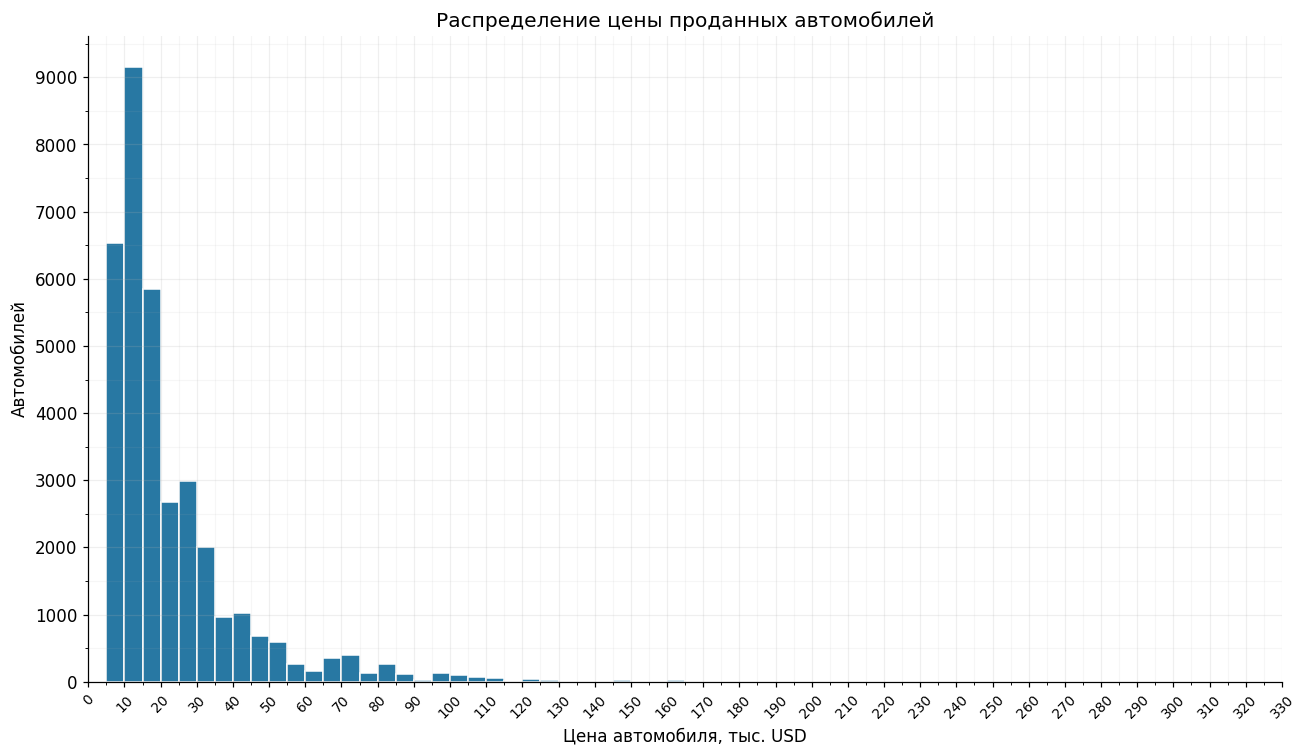

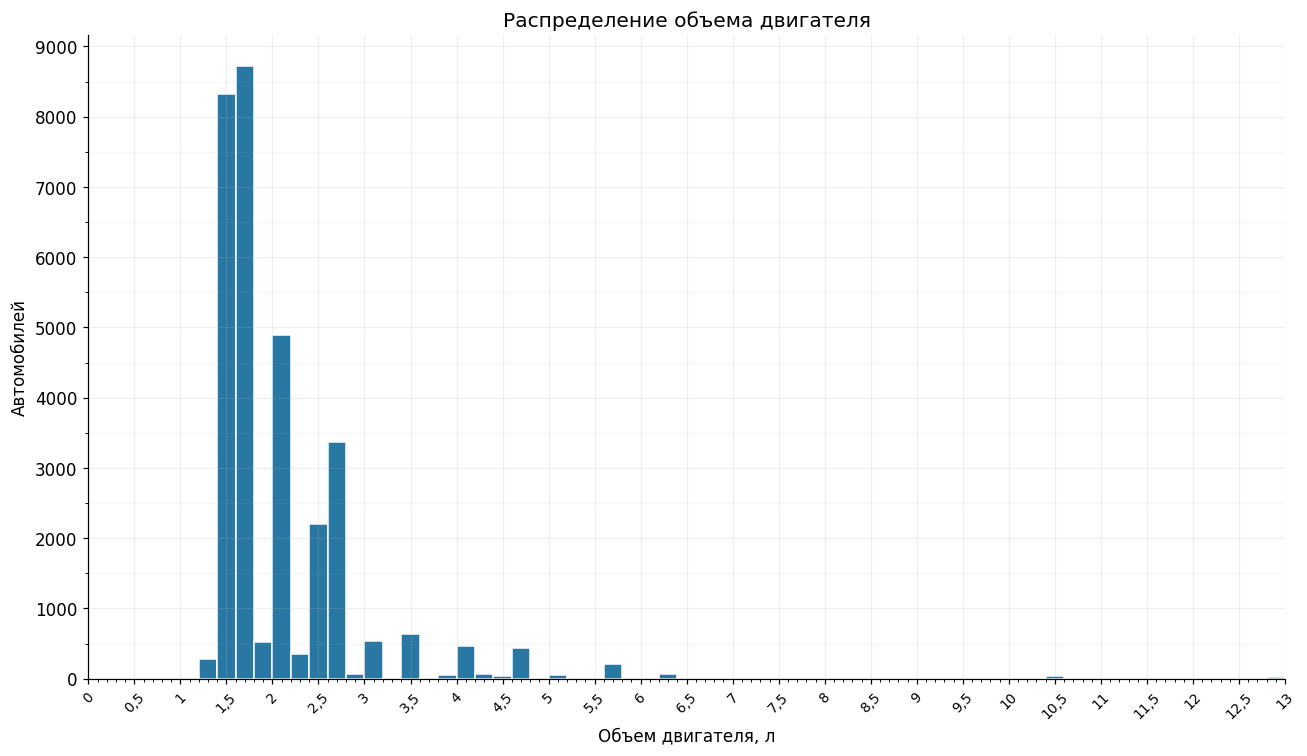

,Строк,Автомобилей,"Стоимость, USD","Доля, %","Средняя цена, USD"
production_year,,,,,
2019,14929,26340,579 272 892.97,75.85,21 992.14
2018,5550,7258,191 572 067.73,20.90,26 394.61
<NA>,228,889,21 181 397.17,2.56,23 826.09
2017,190,206,8 826 104.92,0.59,42 845.17
2016,29,29,712 371.94,0.08,24 564.55
2014,2,2,71 877.95,0.01,35 938.97
2011,1,1,51 813.08,0.00,51 813.08
2013,1,1,44 928.46,0.00,44 928.46


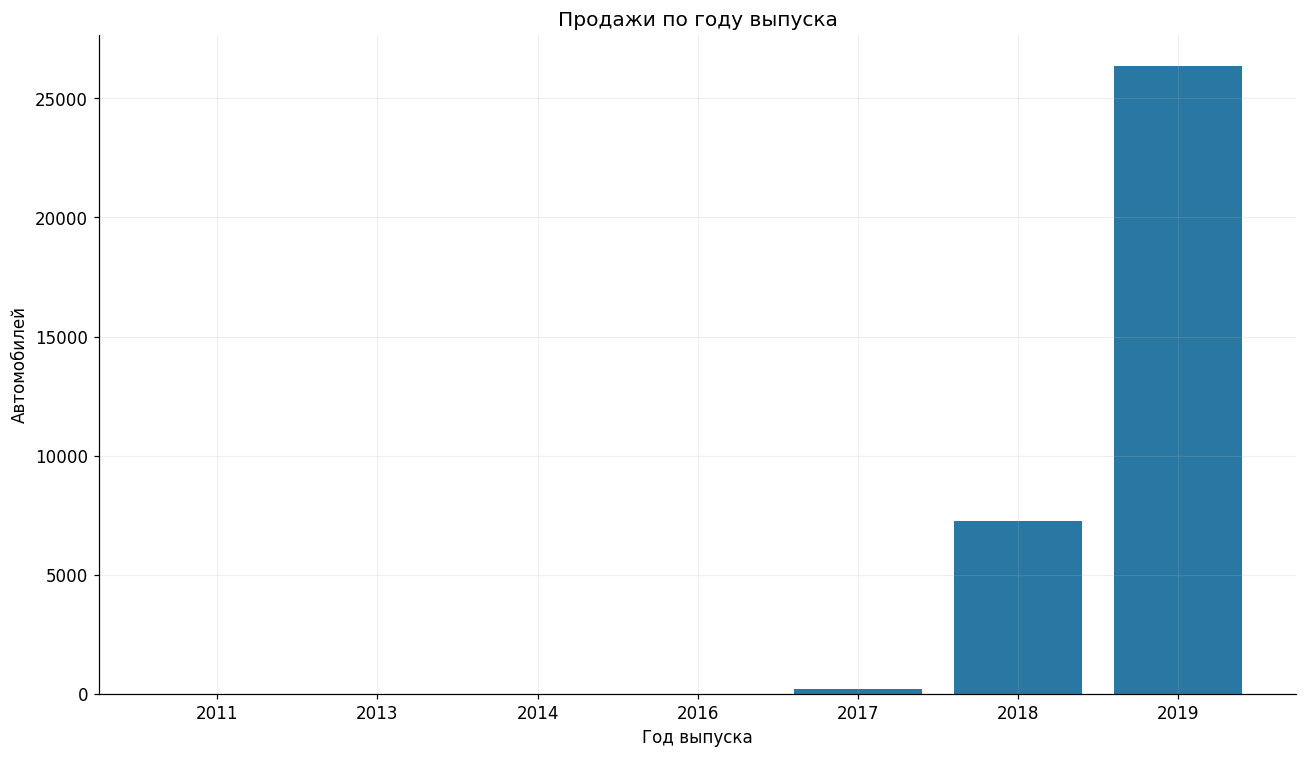

In [15]:
from matplotlib.ticker import MultipleLocator, FuncFormatter

distribution_stats = pd.DataFrame({
    'Цена автомобиля, USD': pd.Series(weighted_values(sales, 'unit_price_usd')).describe(),
    'Объем двигателя, л': pd.Series(weighted_values(sales, 'engine_volume_l')).describe(),
    'Год выпуска': pd.Series(weighted_values(sales, 'production_year')).describe(),
})
display(distribution_stats)
for column, title, xlabel, bins in [
    ('unit_price_usd', 'Распределение цены проданных автомобилей', 'Цена автомобиля, тыс. USD', 45),
    ('engine_volume_l', 'Распределение объема двигателя', 'Объем двигателя, л', 40),
]:
    known = sales.loc[sales[column].notna()]
    values = known[column].to_numpy(dtype=float)
    if column == 'unit_price_usd':
        values = values / 1000
        price_upper = np.ceil(values.max() / 10) * 10
        bins = np.arange(0, price_upper + 5, 5)
    elif column == 'engine_volume_l':
        engine_upper = np.ceil(values.max())
        bins = np.round(np.arange(0, engine_upper + 0.2, 0.2), 1)
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.hist(values, weights=known['quantity'].to_numpy(dtype=int), bins=bins,
            color='#2878a3', edgecolor='white')
    ax.set(title=title, xlabel=xlabel, ylabel='Автомобилей')
    if column == 'unit_price_usd':
        ax.set_xlim(0, price_upper)
        ax.set_xticks(np.arange(0, price_upper + 1, 10))
        ax.xaxis.set_minor_locator(MultipleLocator(5))
        ax.yaxis.set_major_locator(MultipleLocator(1000))
        ax.yaxis.set_minor_locator(MultipleLocator(500))
        ax.tick_params(axis='x', labelrotation=45, labelsize=9)
        ax.grid(which='minor', alpha=0.1)
    elif column == 'engine_volume_l':
        ax.set_xlim(0, engine_upper)
        ax.set_xticks(np.arange(0, engine_upper + 0.5, 0.5))
        ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:g}'.replace('.', ',')))
        ax.xaxis.set_minor_locator(MultipleLocator(0.1))
        ax.yaxis.set_major_locator(MultipleLocator(1000))
        ax.yaxis.set_minor_locator(MultipleLocator(500))
        ax.tick_params(axis='x', labelrotation=45, labelsize=9)
        ax.grid(which='minor', axis='y', alpha=0.1)
    fig.tight_layout()
    plt.show()

years = sales_summary(sales, 'production_year')
show_sales_table(years)
fig, ax = plt.subplots(figsize=(12, 7))
known_years = years.loc[years.index.notna()].sort_index()
ax.bar(known_years.index.astype(int).astype(str), known_years['units'], color='#2878a3')
ax.set(title='Продажи по году выпуска', xlabel='Год выпуска', ylabel='Автомобилей')
fig.tight_layout()
plt.show()

Медианная цена проданного автомобиля — **16 000 USD**, средняя цена положительных продаж —
23 087,41 USD. Половина автомобилей стоит от 11 300 до 27 901,68 USD. Среднее выше медианы,
поскольку в выборке присутствуют дорогие легковые автомобили и коммерческий транспорт.
Максимальная цена — 328 510,97 USD; сама по себе высокая цена не является основанием для удаления.

Медианный объем двигателя — 1,69 л, среднее — 2,09 л. Нули соответствуют четырем электромобилям
в очищенной выборке, верхние значения до 13 л встречаются у коммерческого транспорта.
Для части машин объем неизвестен, поэтому этот вывод относится к заполненным значениям.
Среди положительных продаж 26 340 автомобилей выпущены в 2019 году, 7 258 — в 2018 году;
у 889 автомобилей год выпуска неизвестен.

### 3.3. Бренды, модели и география

Бренды, модели и регионы сортируем по количеству проданных автомобилей. Для этого складываем
значения столбца `quantity` в каждой группе. Одна строка таблицы может описывать как один автомобиль,
так и целую партию, поэтому число строк не показывает, сколько автомобилей продано.

Например, если у бренда A есть 10 строк по одному автомобилю, его объем продаж — 10 автомобилей.
Если у бренда B одна строка с партией из 100 автомобилей, его объем — 100 автомобилей.
Бренд B будет выше в списке, хотя строк у него меньше. Возвраты с отрицательным количеством
уменьшают итоговый объем группы.

Для моделей используем пару «бренд + модель»: одинаковое имя модели у разных производителей
не должно объединять разные автомобили. На графиках показываем десять крупнейших групп,
в таблицах — больше наблюдений.

Бренды с наибольшим объемом продаж


,Строк,Автомобилей,"Стоимость, USD","Доля, %","Средняя цена, USD"
brand,,,,,
Lada,1960,11085,107 766 678.95,31.92,9 721.85
Hyundai,4987,4987,113 312 775.37,14.36,22 721.63
Toyota,3636,3636,149 926 065.91,10.47,41 233.79
Kia,822,2346,45 415 000.00,6.76,19 358.48
Nissan,1042,1651,39 722 742.33,4.75,24 059.81
GAZ,1361,1361,23 823 190.94,3.92,17 504.18
UAZ,781,1217,16 900 203.14,3.50,13 886.77
Renault,1193,1193,16 066 018.10,3.44,13 466.91
Volkswagen,486,1048,21 654 010.18,3.02,20 662.22


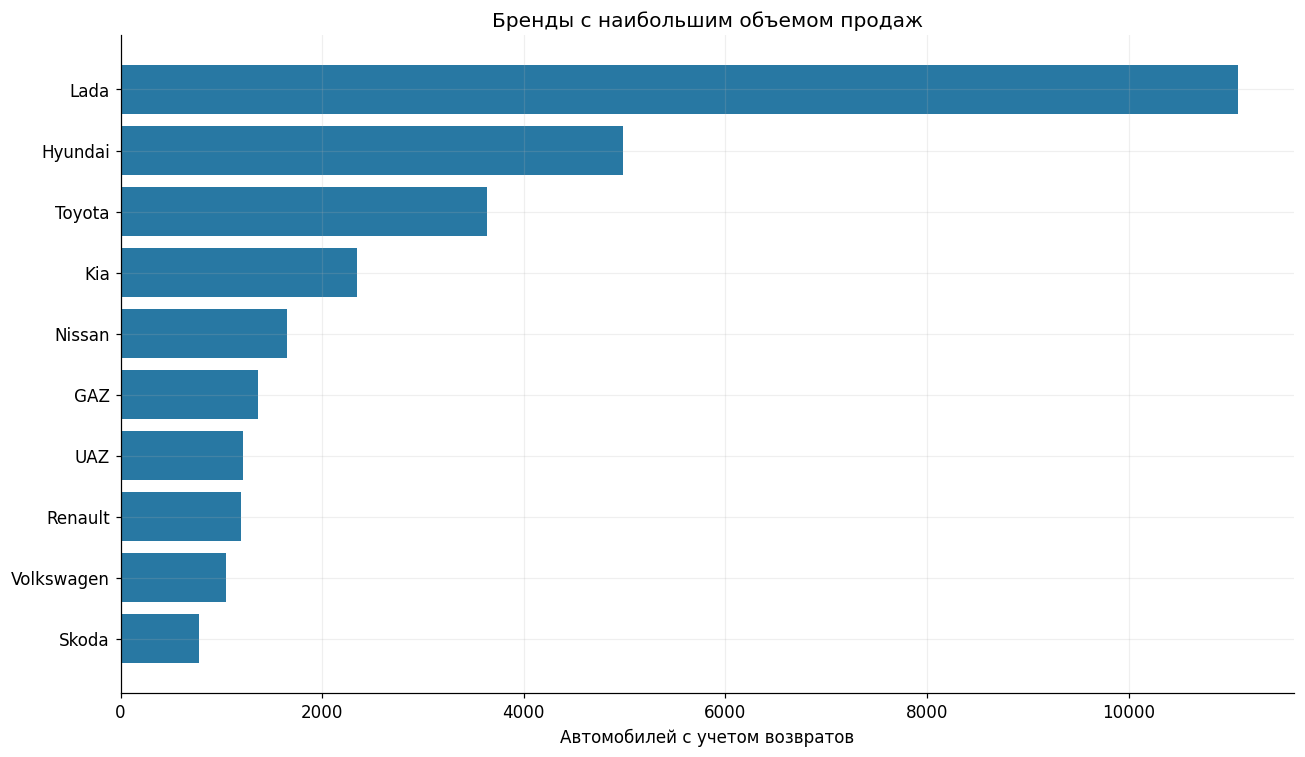

Модели с наибольшим объемом продаж


,Строк,Автомобилей,"Стоимость, USD","Доля, %","Средняя цена, USD"
brand_model,,,,,
Lada Granta,461,3663,26 664 805.26,10.55,7 279.50
Lada Vesta,624,2650,31 081 473.68,7.63,11 728.86
Lada 4x4,251,2469,22 338 600.00,7.11,9 047.63
Lada Largus,265,1682,19 161 900.00,4.84,11 392.33
Hyundai Tucson,1370,1370,36 314 314.26,3.95,26 506.80
Hyundai Accent,1246,1246,20 837 341.39,3.59,16 723.39
Toyota Camry,1120,1120,37 396 000.00,3.23,33 389.29
Hyundai Creta,1054,1054,21 112 880.07,3.04,20 031.20
Kia Rio,182,993,13 755 500.00,2.86,13 852.47


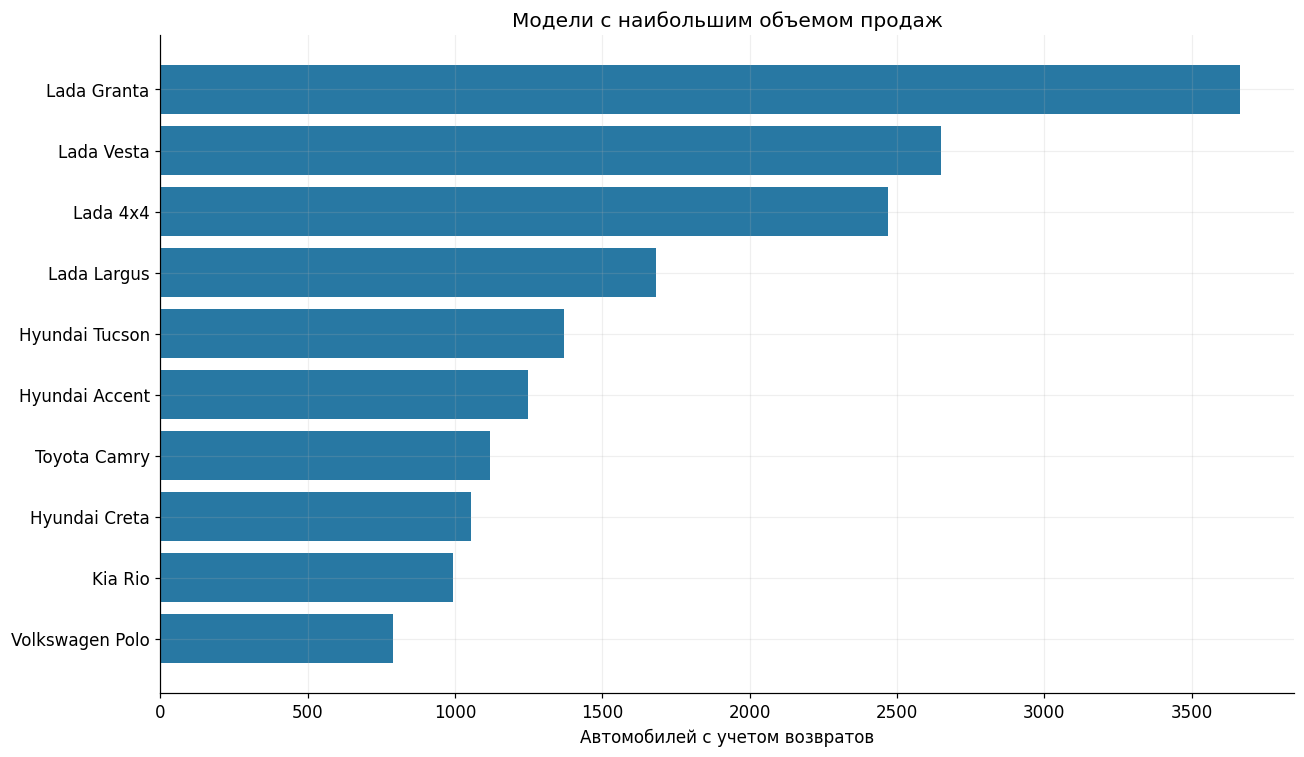

Регионы с наибольшим объемом продаж


,Строк,Автомобилей,"Стоимость, USD","Доля, %","Средняя цена, USD"
region,,,,,
Алматы,4912,7682,240 248 212.74,22.12,31 274.18
Нур-Султан,3776,5682,154 143 367.05,16.36,27 128.36
Атырау,1272,2503,47 873 558.78,7.21,19 126.47
Караганда,1447,2355,45 234 245.68,6.78,19 207.75
Шымкент,1449,2318,46 509 184.69,6.68,20 064.36
Костанай,1401,2212,45 524 698.81,6.37,20 580.79
Усть-Каменогорск,928,1865,35 078 917.15,5.37,18 809.07
Уральск,1056,1743,33 678 767.49,5.02,19 322.30
Актобе,964,1422,31 748 209.64,4.10,22 326.45


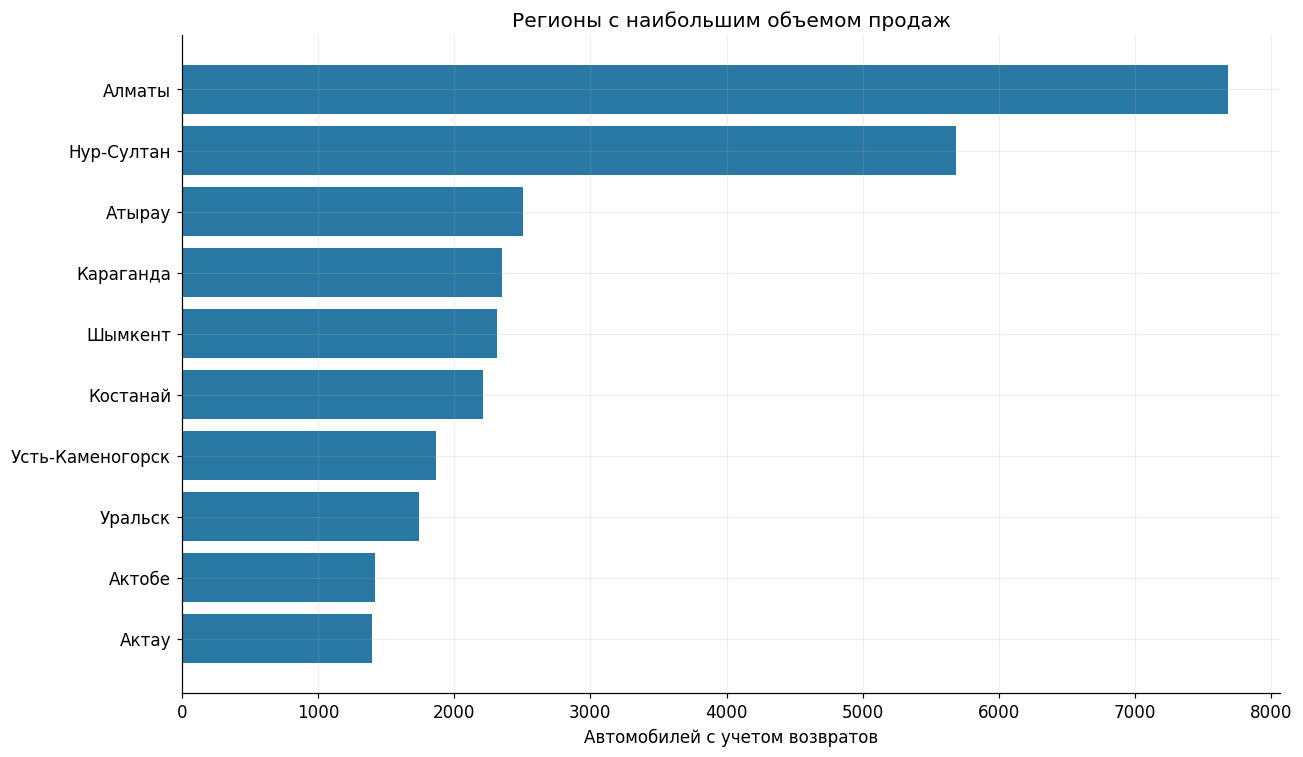

In [16]:
market['brand_model'] = market['brand'].astype('string') + ' ' + market['model'].astype('string')
brand_sales = sales_summary(market, 'brand')
model_sales = sales_summary(market, 'brand_model')
region_sales = sales_summary(market, 'region')
company_sales = sales_summary(market, 'company')

for table, title in [
    (brand_sales, 'Бренды с наибольшим объемом продаж'),
    (model_sales, 'Модели с наибольшим объемом продаж'),
    (region_sales, 'Регионы с наибольшим объемом продаж'),
]:
    print(title)
    show_sales_table(table.head(15))
    top = table.head(10).sort_values('units')
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.barh(top.index.astype(str), top['units'], color='#2878a3')
    ax.set(title=title, xlabel='Автомобилей с учетом возвратов', ylabel='')
    fig.tight_layout()
    plt.show()

В основном сценарии лидируют Lada — 11 085 автомобилей, Hyundai — 4 987 и Toyota — 3 636.
При этом по стоимости продаж первая Toyota: 149,93 млн USD, тогда как у Lada — 107,77 млн USD.
Первое место по количеству не обязательно означает первое место по стоимости.

Крупнейшая модель — Lada Granta, 3 663 автомобиля. Далее идут Lada Vesta — 2 650
и Lada 4x4 — 2 469. Результат зависит от сохранения партий и принятого удаления повторов.
Больше всего автомобилей в Алматы — 7 682 и Нур-Султане — 5 682;
вместе эти города составляют 38,49% чистого объема выборки.

### 3.4. Топливо, коробки, привод, сегменты и страна производства

Неизвестные категории выводим отдельной группой «Неизвестно». Ее долю считаем от всего объема,
чтобы неполнота характеристик не исчезала из сравнения. Страна производства характеризует место
изготовления автомобиля, а не страну происхождения бренда.

Продажи по виду топлива


,Строк,Автомобилей,"Стоимость, USD","Доля, %","Средняя цена, USD"
fuel_type,,,,,
F,18421,30818,678 853 062.86,88.75,22 027.81
Неизвестно,1850,2986,69 910 457.99,8.60,23 412.75
D,642,903,51 186 930.59,2.60,56 685.42
HYB,14,14,1 096 389.12,0.04,78 313.51
E,4,4,651 025.41,0.01,162 756.35


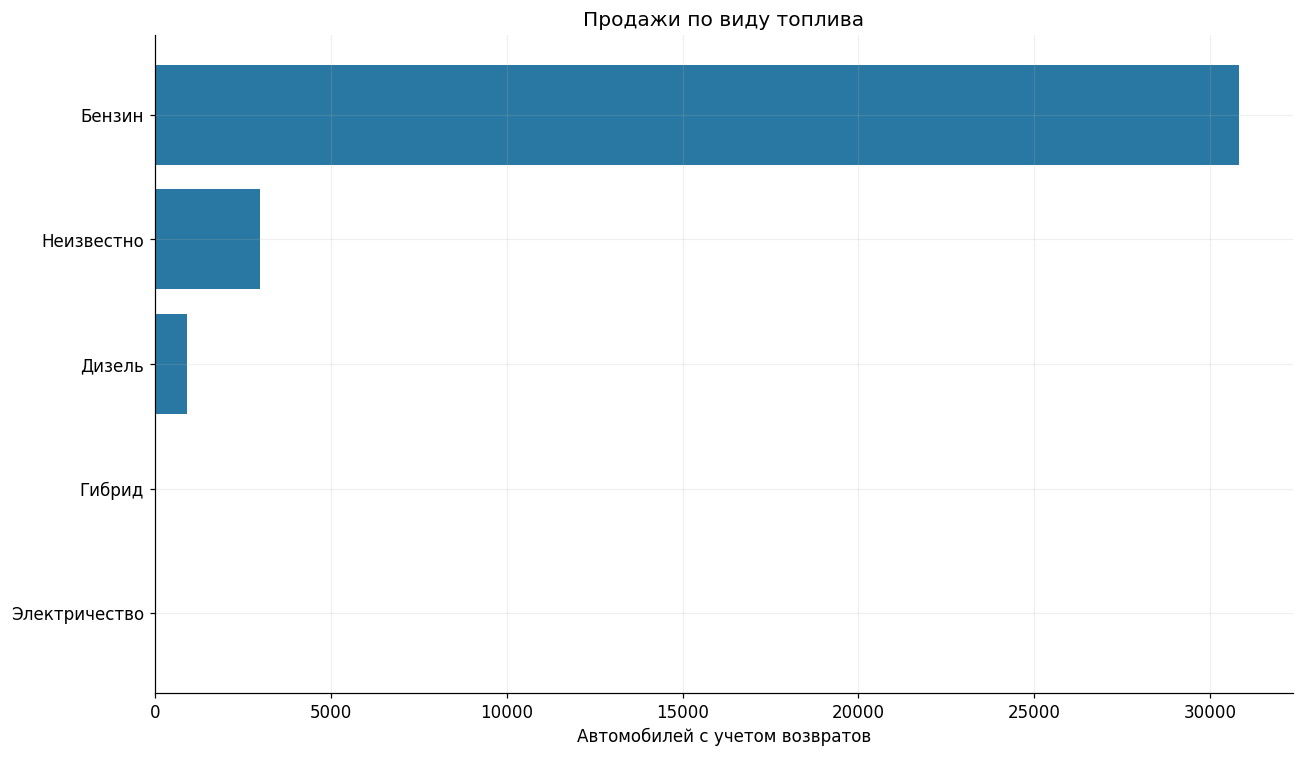

Продажи по коробке передач


,Строк,Автомобилей,"Стоимость, USD","Доля, %","Средняя цена, USD"
transmission,,,,,
Автомат,13836,17859,531 033 409.80,51.43,29 734.78
Механика,5268,13904,195 934 187.03,40.04,14 091.93
Неизвестно,1827,2962,74 730 269.14,8.53,25 229.67


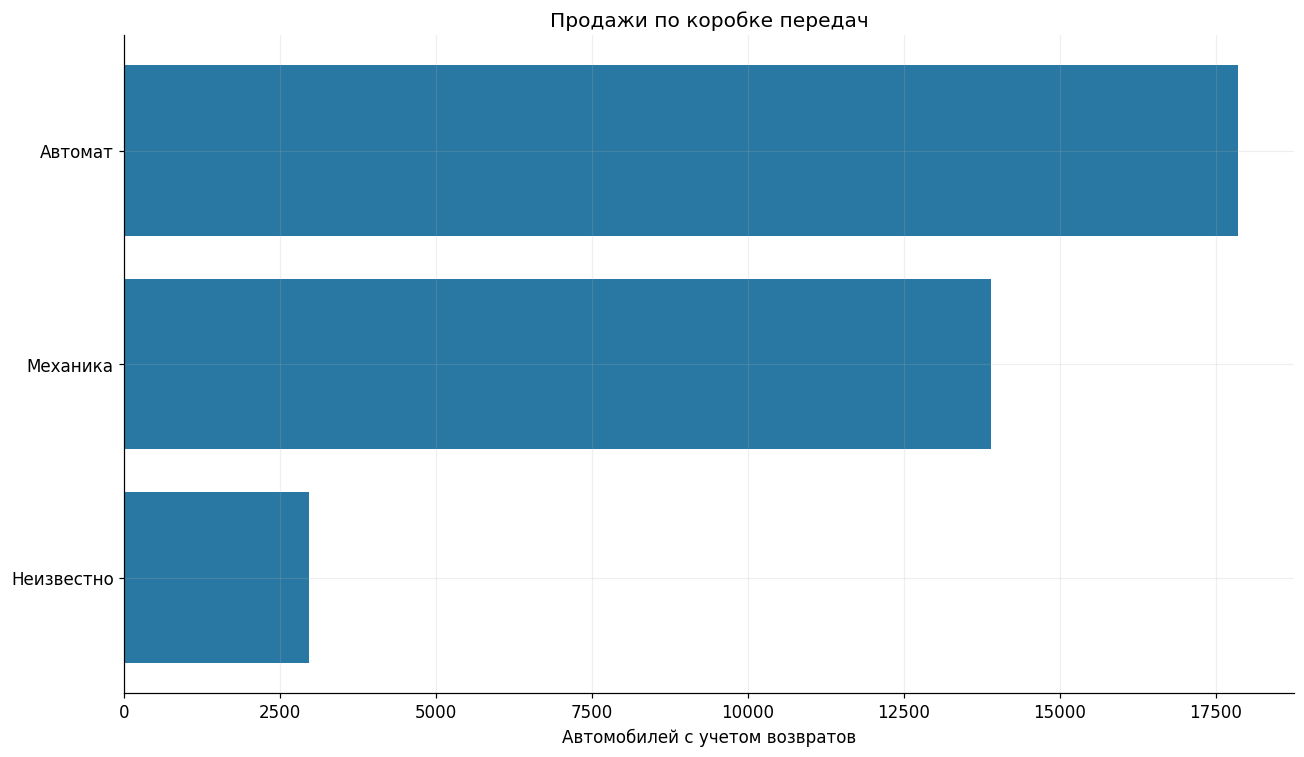

Продажи по типу привода


,Строк,Автомобилей,"Стоимость, USD","Доля, %","Средняя цена, USD"
drive_type,,,,,
FWD,4510,13091,185 738 758.72,37.70,14 188.28
4WD,8648,12499,398 410 714.19,35.99,31 875.41
2WD,4236,4305,85 750 212.86,12.40,19 918.75
Неизвестно,2245,3518,106 723 402.04,10.13,30 336.38
RWD,1292,1312,25 074 778.15,3.78,19 111.87


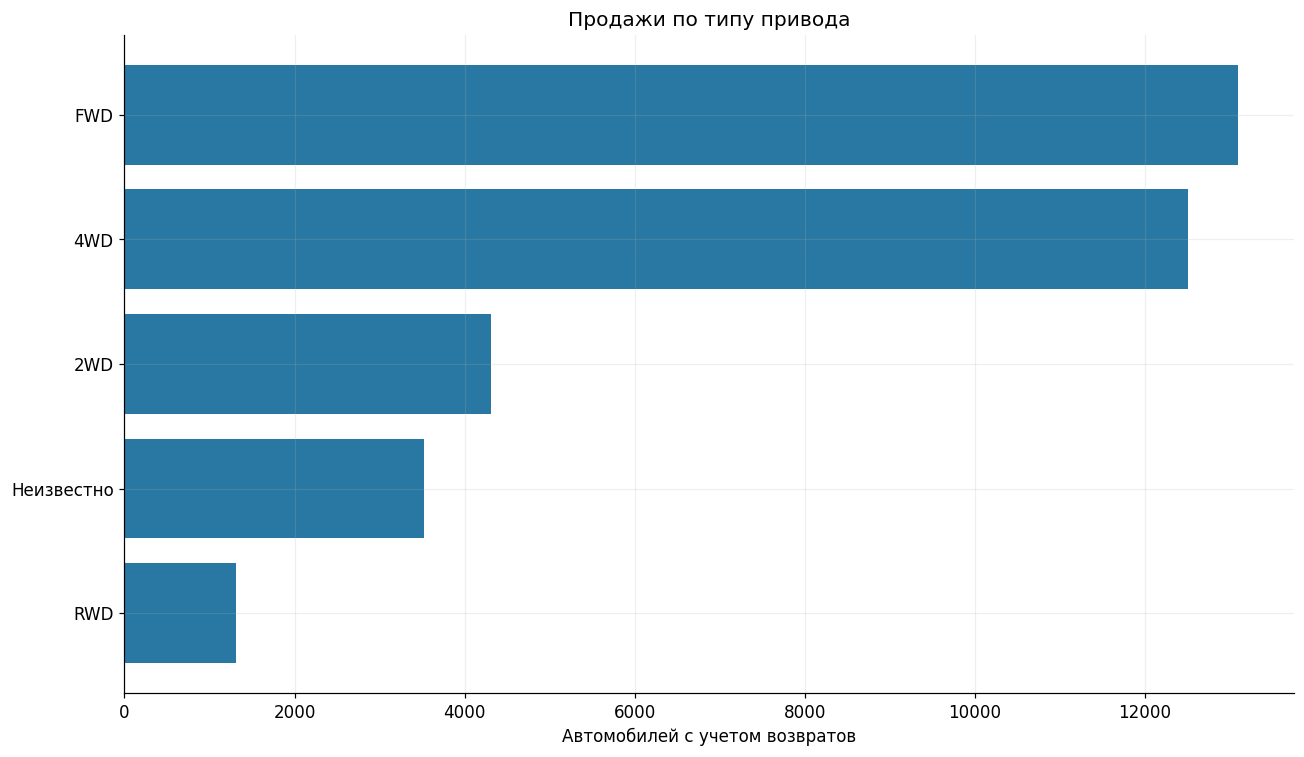

Продажи по сегментам


,Строк,Автомобилей,"Стоимость, USD","Доля, %","Средняя цена, USD"
segment_2013,,,,,
Легковые автомобили,7509,15008,237 043 242.32,43.22,15 794.46
Внедорожники,10094,14047,420 733 988.61,40.45,29 951.88
Коммерческие автомобили,2569,3487,110 247 450.64,10.04,31 616.71
Минивэны,376,1798,22 213 833.60,5.18,12 354.75
Пикапы,383,385,11 459 350.79,1.11,29 764.55


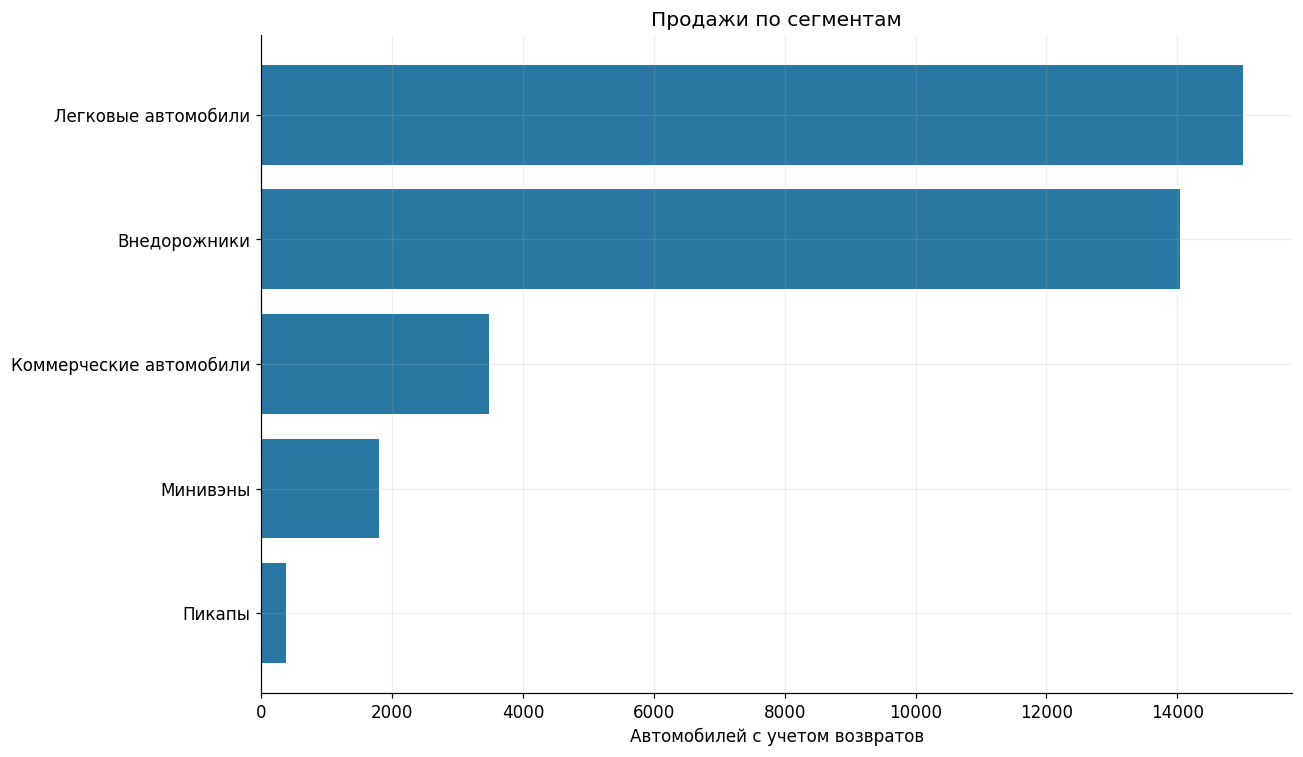

Продажи по стране производства


,Строк,Автомобилей,"Стоимость, USD","Доля, %","Средняя цена, USD"
country,,,,,
KAZ,10293,22178,362 941 376.42,63.87,16 364.93
RUS,6507,7999,180 997 978.82,23.04,22 627.58
JPN,2473,2490,138 025 444.29,7.17,55 431.91
USA,257,475,32 980 036.77,1.37,69 431.66
TUR,434,434,12 840 896.67,1.25,29 587.32
THA,383,394,13 645 663.82,1.13,34 633.66
DEU,252,344,25 302 826.70,0.99,73 554.73
GBR,179,188,16 470 701.77,0.54,87 610.12
AUT,33,69,9 928 951.63,0.20,143 897.85


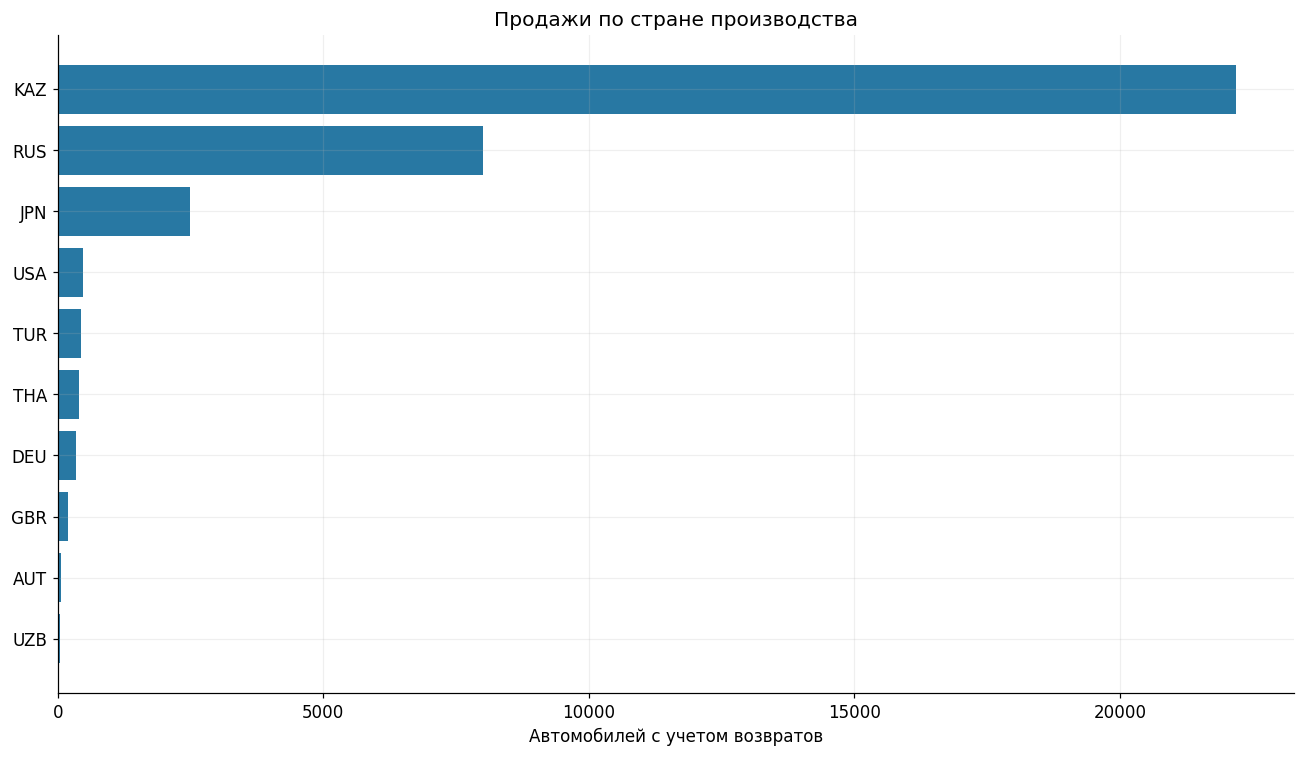

In [17]:
category_tables = {}
for column, title in [
    ('fuel_type', 'Продажи по виду топлива'),
    ('transmission', 'Продажи по коробке передач'),
    ('drive_type', 'Продажи по типу привода'),
    ('segment_2013', 'Продажи по сегментам'),
    ('country', 'Продажи по стране производства'),
]:
    temp = market.copy()
    temp[column] = temp[column].astype('string').fillna('Неизвестно')
    summary = sales_summary(temp, column)
    category_tables[column] = summary
    print(title)
    show_sales_table(summary)
    plotted = summary.head(10).sort_values('units')
    labels = plotted.index.to_series().replace({'F': 'Бензин', 'D': 'Дизель',
                                                'E': 'Электричество', 'HYB': 'Гибрид'})
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.barh(labels.astype(str), plotted['units'], color='#2878a3')
    ax.set(title=title, xlabel='Автомобилей с учетом возвратов', ylabel='')
    fig.tight_layout()
    plt.show()

Бензиновые автомобили составляют 88,75% чистого объема.
Для 2 986 автомобилей вид топлива неизвестен, поэтому редкие категории нельзя считать полностью
описанными. Автоматические коробки — 17 859 автомобилей, механические — 13 904;
еще у 2 962 автомобилей тип коробки неизвестен.

Крупнейшие сегменты — легковые автомобили, 15 008, и внедорожники, 14 047.
Коммерческий транспорт занимает 3 487 автомобилей. Он включен в рынок по условию задания,
поэтому общая средняя цена смешивает разные типы техники.
В Казахстане произведено 22 178 автомобилей, или 63,87% внутреннего среза.
Группа `2WD` не объединяется с передним приводом: в исходной записи ведущая ось неизвестна.

### 3.5. Динамика рынка и связь цены с характеристиками

Сравниваем календарные месяцы с января по сентябрь. Девять месяцев одного года не позволяют
отделить устойчивую сезонность от разовых изменений и особенностей учета.
Месячная средняя цена также зависит от состава проданных моделей.

,Строк,Автомобилей,"Стоимость, USD","Доля, %","Средняя цена, USD"
sale_date,,,,,
2019-01-31,1821,2953,67 443 577.91,8.50,22 839.00
2019-02-28,1839,3193,69 570 790.28,9.20,21 788.53
2019-03-31,2153,3437,79 726 412.64,9.90,23 196.51
2019-04-30,2593,4282,98 131 069.72,12.33,22 917.11
2019-05-31,2618,4257,104 823 982.76,12.26,24 623.91
2019-06-30,2477,4177,98 883 773.76,12.03,23 673.40
2019-07-31,2584,4432,102 384 394.30,12.76,23 101.17
2019-08-31,2431,4250,95 117 393.75,12.24,22 380.56
2019-09-30,2415,3744,85 616 470.84,10.78,22 867.65


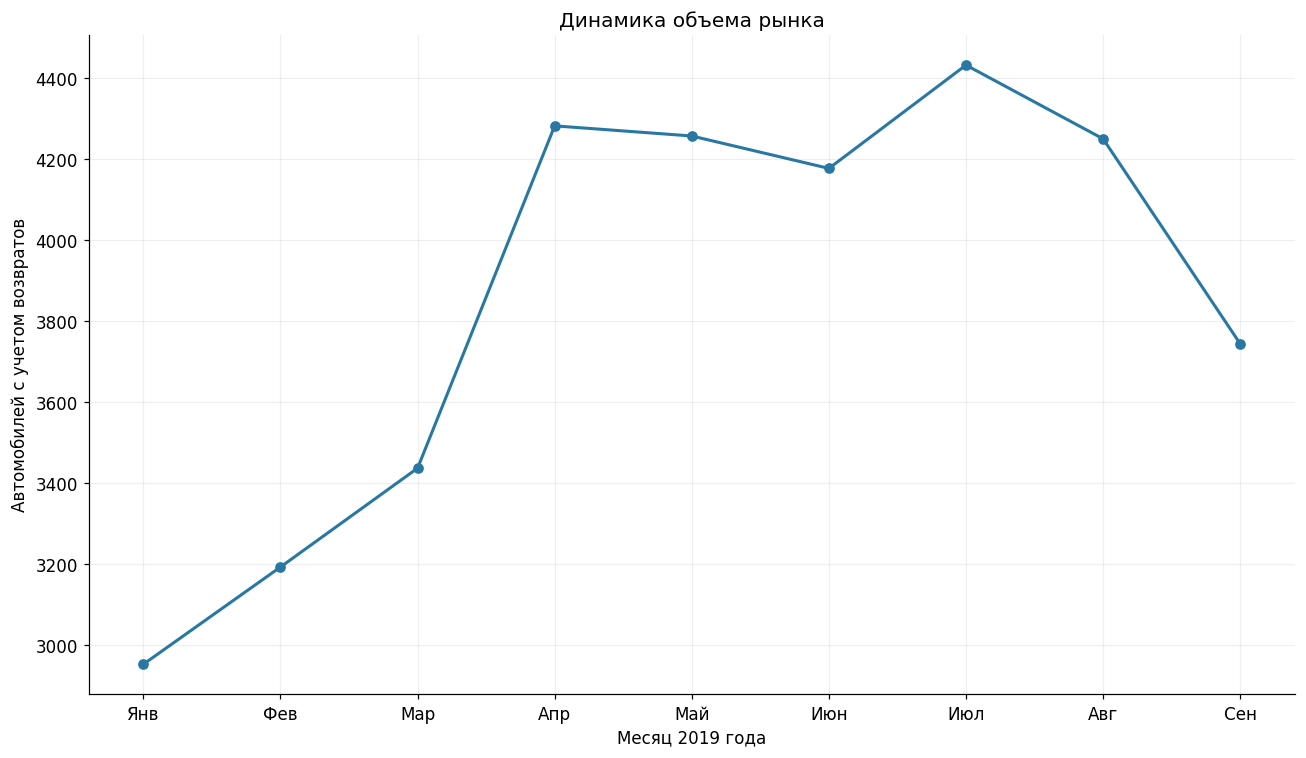

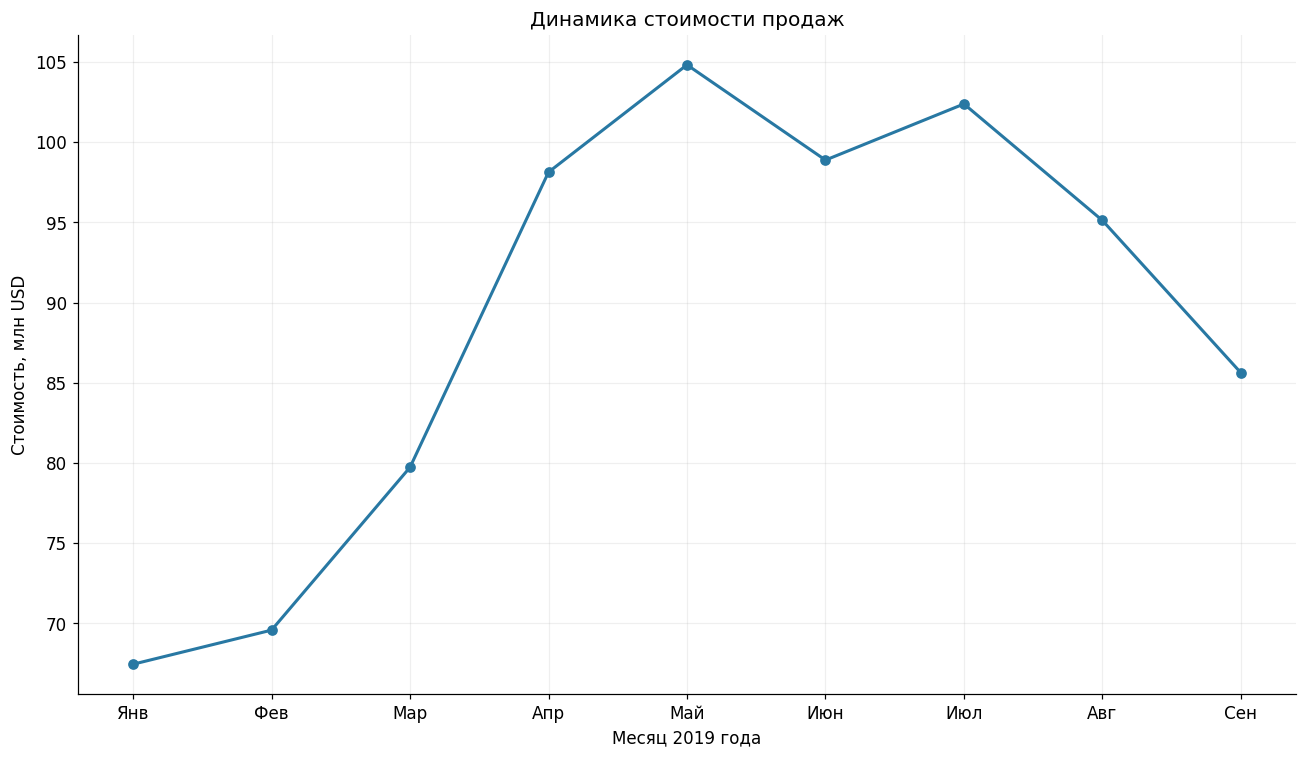

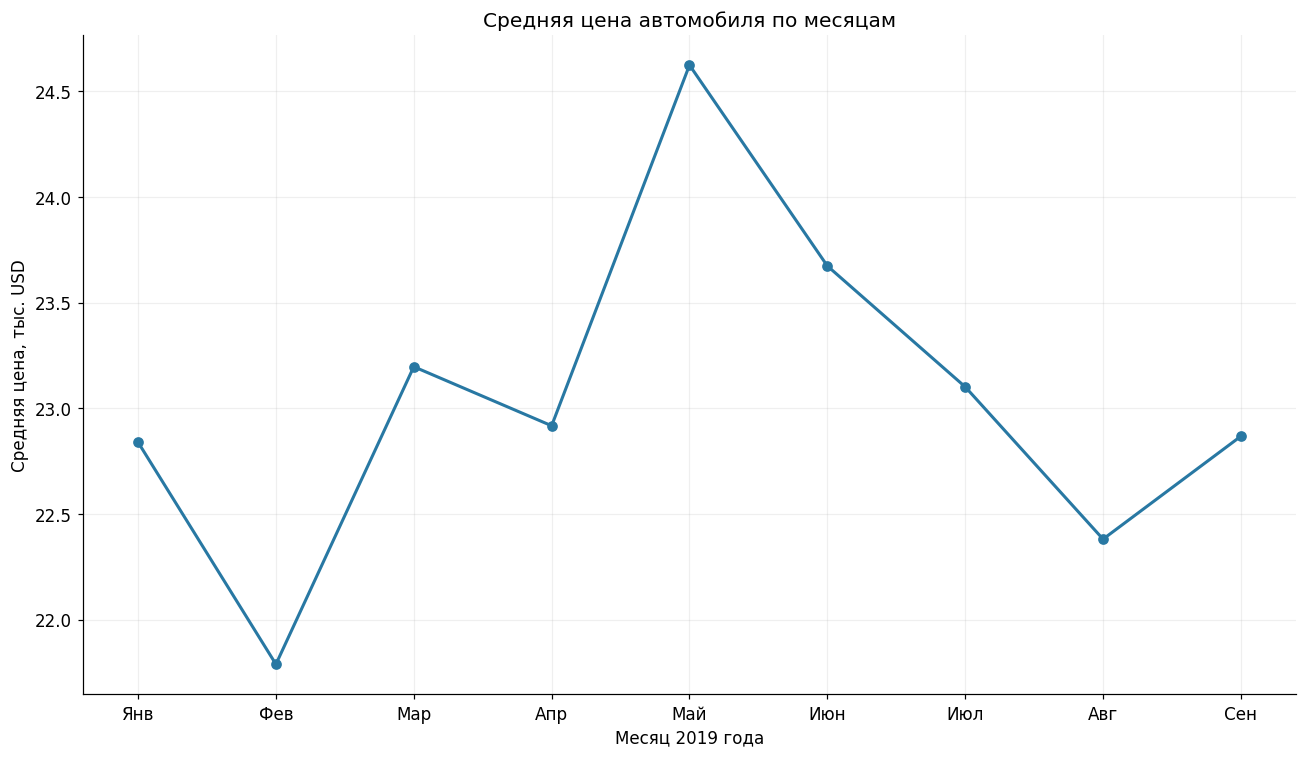

,Объем двигателя,Цена
Объем двигателя,1.00,0.73
Цена,0.73,1.00


Автомобилей в расчете корреляции: 31400


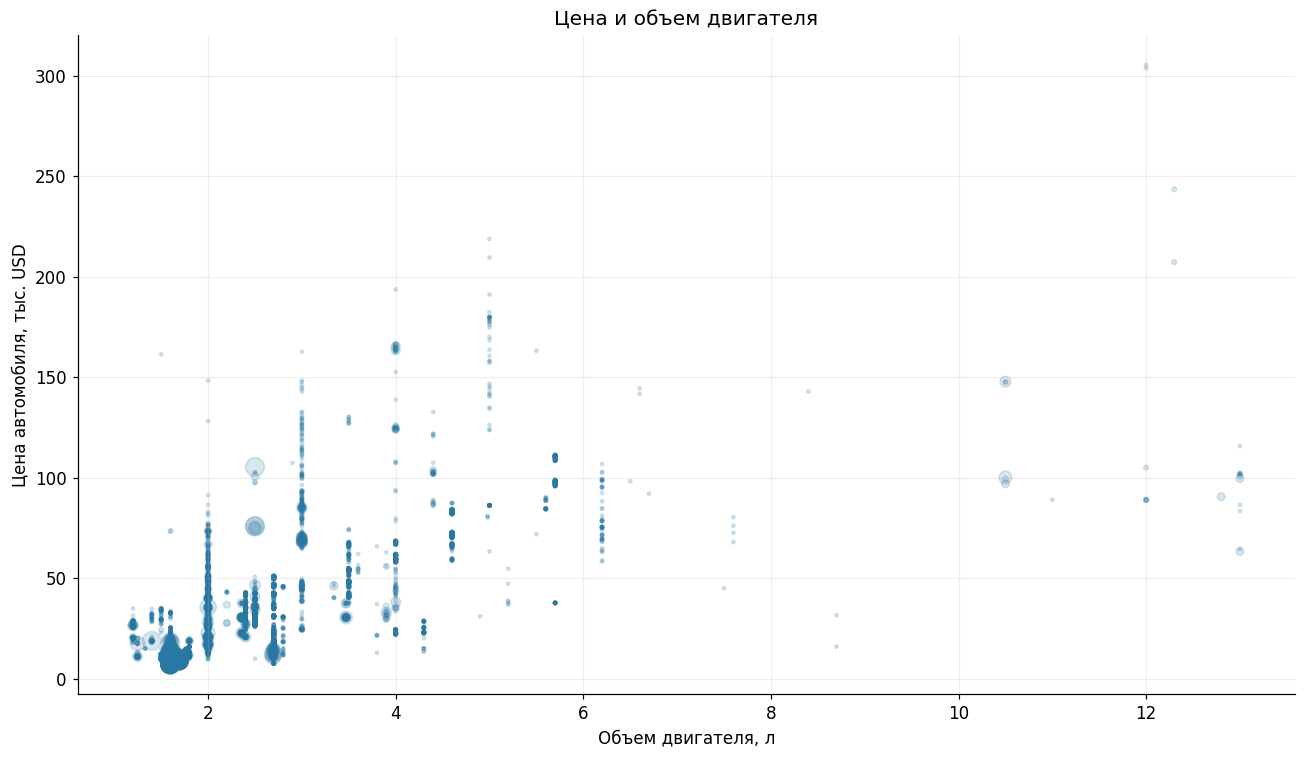

Размер точки растет с количеством, но ограничен для читаемости; данные не исключены


In [18]:
monthly = sales_summary(market, 'sale_date').sort_index()
show_sales_table(monthly)
month_labels = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн', 'Июл', 'Авг', 'Сен']
for column, title, ylabel, scale in [
    ('units', 'Динамика объема рынка', 'Автомобилей с учетом возвратов', 1),
    ('revenue', 'Динамика стоимости продаж', 'Стоимость, млн USD', 1e6),
    ('avg_price', 'Средняя цена автомобиля по месяцам', 'Средняя цена, тыс. USD', 1000),
]:
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.plot(month_labels, monthly[column] / scale, marker='o', color='#2878a3', linewidth=2)
    ax.set(title=title, xlabel='Месяц 2019 года', ylabel=ylabel)
    fig.tight_layout()
    plt.show()

# Корреляция учитывает количество автомобилей и только известные пары значений
known_pairs = sales.loc[sales['engine_volume_l'].notna() & sales['engine_volume_l'].gt(0)]
pairs = pd.DataFrame({
    'Объем двигателя': np.repeat(known_pairs['engine_volume_l'].to_numpy(dtype=float), known_pairs['quantity'].to_numpy(dtype=int)),
    'Цена': np.repeat(known_pairs['unit_price_usd'].to_numpy(dtype=float), known_pairs['quantity'].to_numpy(dtype=int)),
})
display(pairs.corr(method='spearman'))
print('Автомобилей в расчете корреляции:', len(pairs))
fig, ax = plt.subplots(figsize=(12, 7))
ax.scatter(known_pairs['engine_volume_l'].astype(float), known_pairs['unit_price_usd'].astype(float) / 1000,
           s=np.minimum(known_pairs['quantity'].astype(float), 30) * 5, alpha=0.18, color='#2878a3')
ax.set(title='Цена и объем двигателя', xlabel='Объем двигателя, л', ylabel='Цена автомобиля, тыс. USD')
fig.tight_layout()
plt.show()
print('Размер точки растет с количеством, но ограничен для читаемости; данные не исключены')

Максимальный чистый объем — в июле, 4 432 автомобиля, минимальный — в январе, 2 953.
В сентябре объем снижается до 3 744 автомобилей. Наибольшая стоимость продаж приходится на май —
104,82 млн USD. Месячная средняя цена находится примерно между 21,79 и 24,62 тыс. USD.

Корреляция Спирмена между ценой и объемом двигателя составляет около 0,73 по 31 400 автомобилям
с известным положительным объемом. График показывает положительную связь, но одинаковый объем соответствует
разным ценам. Здесь смешаны марки, классы и типы техники, поэтому корреляция не является оценкой
самостоятельного влияния двигателя на цену.

### 3.6. Возврат и крупные партии

Отдельно рассматриваем самый большой объем, не устанавливая произвольного порога удаления.
Флаг партии означает лишь количество больше одного автомобиля в строке.
В задании 100 Skoda приведены как пример заказа таксопарка; в самой выгрузке назначения покупки нет,
поэтому по этим данным можно подтвердить только размер партии.

In [19]:
display(market.loc[market['is_return'], ['source_row', 'brand', 'model', 'region', 'quantity',
                                      'unit_price_usd', 'total_price_usd']])
display(market.nlargest(10, 'quantity')[['source_row', 'brand', 'model', 'region', 'quantity',
                                       'unit_price_usd', 'total_price_usd']])
batch_summary = market.groupby('is_batch').agg(rows=('source_row', 'size'),
                                               units=('quantity', 'sum'), revenue=('total_price_usd', 'sum'))
batch_summary['share_pct'] = batch_summary['units'] / market['quantity'].sum() * 100
display(batch_summary.rename(index={False: 'Остальные записи, включая возврат', True: 'Партии больше одной машины'}))

,source_row,brand,model,region,quantity,unit_price_usd,total_price_usd
15144,25730,Skoda,Superb,Тараз,-1,35 588.25,-35 588.25


,source_row,brand,model,region,quantity,unit_price_usd,total_price_usd
8870,16887,Lada,4x4,Тараз,115,9 000.00,1 035 000.00
14974,25557,Skoda,Octavia,Тараз,100,18 700.00,1 870 000.00
20312,38410,Volkswagen,Polo,Алматы,79,15 967.85,1 261 459.99
8953,16970,Lada,4x4,Атырау,66,9 000.00,594 000.00
8288,16301,Kia,Rio,Алматы,63,13 500.00,850 500.00
20327,38425,Volkswagen,Polo,Алматы,62,15 774.42,978 014.24
20328,38426,Volkswagen,Polo,Алматы,62,15 759.71,977 101.92
8352,16365,Kia,Rio,Алматы,60,13 500.00,810 000.00
8843,16860,Lada,4x4,Караганда,54,9 000.00,486 000.00
9509,17527,Lada,Largus,Алматы,51,11 300.00,576 300.00


,rows,units,revenue,share_pct
is_batch,,,,
"Остальные записи, включая возврат",18186,18184,528 940 672.90,52.37
Партии больше одной машины,2745,16541,272 757 193.07,47.63


Возврат относится к Skoda Superb в Таразе: количество −1 и стоимость −35 588,25 USD.
Крупнейшие партии — 115 Lada 4x4 и 100 Skoda Octavia в Таразе, а также 79 Volkswagen Polo в Алматы.
Во всех случаях количество согласуется со стоимостью. Эти строки сохранены и учитываются
с полным количеством автомобилей.

## 4. Позиция «Меркур Авто»

### 4.1. Общие показатели и способ отбора

Основной способ отбора в этом разделе — нормализованный столбец `company`.
Он соответствует инструкции об объединении вариантов названия компании.
Дополнительно проверим записи с Mercur Auto в имени дилера: это другой срез, его нельзя
автоматически приравнять к компании или сложить с ней.

Все доли ниже рассчитаны внутри очищенного внутреннего рынка за те же девять месяцев.

In [20]:
def kpi(frame):
    units = frame['quantity'].sum()
    revenue = frame['total_price_usd'].sum()
    return pd.Series({
        'Строк': len(frame), 'Автомобилей с учетом возвратов': units,
        'Стоимость продаж, USD': revenue, 'Средняя цена автомобиля, USD': revenue / units,
        'Доля по количеству, %': units / market['quantity'].sum() * 100,
        'Доля по стоимости, %': revenue / market['total_price_usd'].sum() * 100,
    })

kpi_table = pd.DataFrame({'Весь рынок': kpi(market), 'Меркур Авто': kpi(mercur),
                          'Остальные компании': kpi(market.loc[~market['company'].eq('Меркур Авто')])})
display(kpi_table)
show_sales_table(company_sales.head(15))
print('Место Меркур Авто по количеству:', int(company_sales['units'].rank(ascending=False, method='min').loc['Меркур Авто']))

,Весь рынок,Меркур Авто,Остальные компании
Строк,20 931.00,387.00,20 544.00
Автомобилей с учетом возвратов,34 725.00,394.00,34 331.00
"Стоимость продаж, USD",801 697 865.97,15 121 529.04,786 576 336.93
"Средняя цена автомобиля, USD",23 087.05,38 379.52,22 911.55
"Доля по количеству, %",100.00,1.13,98.87
"Доля по стоимости, %",100.00,1.89,98.11


,Строк,Автомобилей,"Стоимость, USD","Доля, %","Средняя цена, USD"
company,,,,,
БИПЭК АВТО,3593,15098,185 168 228.45,43.48,12 264.42
Astana Motors,4988,4988,113 343 783.32,14.36,22 723.29
Toyota Motor Kazakhstan,4275,4275,190 620 156.72,12.31,44 589.51
Вираж,2017,2017,32 523 537.88,5.81,16 124.71
Nissan Manufacturing RUS,1115,1724,44 233 125.50,4.96,25 657.27
Renault Россия,1193,1193,16 066 018.10,3.44,13 466.91
Volkswagen Group Rus,100,655,13 355 742.81,1.89,20 390.45
Allur Auto,516,518,13 749 618.07,1.49,26 543.66
Автоцентр-Бавария,224,454,29 219 721.33,1.31,64 360.62


Место Меркур Авто по количеству: 11


По полю компании «Меркур Авто» реализовало **394 автомобиля** на **15,12 млн USD**.
Это **1,13% количества** и **1,89% стоимости** рынка.
По количеству компания занимает 11-е место среди компаний очищенной выборки.

Средняя цена автомобиля — **38 379,52 USD**, рыночная — **23 087,05 USD**.
Разница составляет 66,24%, однако сама по себе не доказывает эффективность
продаж: она может быть связана с ассортиментом. Прибыль, маржа и затраты в данных отсутствуют.

### 4.2. Доли по брендам, регионам, сегментам и классам

Для каждой группы рассчитываем две разные доли. Доля рынка показывает, какую часть продаж
группы обеспечивает «Меркур Авто». Доля в ассортименте показывает, какую часть продаж самой
компании составляет группа. Знаменатели у этих показателей разные.

Бренды


,Автомобилей на рынке,"Стоимость рынка, USD",Автомобилей Меркур,"Стоимость Меркур, USD","Доля Меркур в группе, %","Группа в рынке, %","Группа в Меркур, %","Средняя цена рынка, USD","Средняя цена Меркур, USD"
brand,,,,,,,,,
Volkswagen,1048,21 654 010.18,294,6 299 195.92,28.05,3.02,74.62,20 662.22,21 425.84
Porsche,52,5 113 512.70,52,5 113 512.70,100.00,0.15,13.20,98 336.78,98 336.78
Audi,48,3 708 820.43,48,3 708 820.43,100.00,0.14,12.18,77 267.09,77 267.09
ANKAI,67,5 907 782.63,0,0.00,0.00,0.19,0.00,88 175.86,<NA>
Mazda,276,8 137 024.76,0,0.00,0.00,0.79,0.00,29 481.97,<NA>
Mercedes-Benz,150,14 907 907.29,0,0.00,0.00,0.43,0.00,99 386.05,<NA>
Mercedes-Benz Trucks,46,3 610 272.10,0,0.00,0.00,0.13,0.00,78 484.18,<NA>
Mini,16,483 952.96,0,0.00,0.00,0.05,0.00,30 247.06,<NA>
Mitsubishi,423,14 245 533.06,0,0.00,0.00,1.22,0.00,33 677.38,<NA>


Регионы


,Автомобилей на рынке,"Стоимость рынка, USD",Автомобилей Меркур,"Стоимость Меркур, USD","Доля Меркур в группе, %","Группа в рынке, %","Группа в Меркур, %","Средняя цена рынка, USD","Средняя цена Меркур, USD"
region,,,,,,,,,
Алматы,7682,240 248 212.74,251,11 600 584.29,3.27,22.12,63.71,31 274.18,46 217.47
Нур-Султан,5682,154 143 367.05,51,1 502 141.15,0.90,16.36,12.94,27 128.36,29 453.75
Атырау,2503,47 873 558.78,43,790 024.51,1.72,7.21,10.91,19 126.47,18 372.66
Караганда,2355,45 234 245.68,21,399 332.52,0.89,6.78,5.33,19 207.75,19 015.83
Уральск,1743,33 678 767.49,14,290 651.93,0.80,5.02,3.55,19 322.30,20 760.85
Костанай,2212,45 524 698.81,14,538 794.64,0.63,6.37,3.55,20 580.79,38 485.33
Актау,1400,27 068 594.67,0,0.00,0.00,4.03,0.00,19 334.71,<NA>
Рудный,21,219 816.79,0,0.00,0.00,0.06,0.00,10 467.47,<NA>
Шымкент,2318,46 509 184.69,0,0.00,0.00,6.68,0.00,20 064.36,<NA>


Сегменты


,Автомобилей на рынке,"Стоимость рынка, USD",Автомобилей Меркур,"Стоимость Меркур, USD","Доля Меркур в группе, %","Группа в рынке, %","Группа в Меркур, %","Средняя цена рынка, USD","Средняя цена Меркур, USD"
segment_2013,,,,,,,,,
Легковые автомобили,15008,237 043 242.32,234,5 809 570.89,1.56,43.22,59.39,15 794.46,24 827.23
Внедорожники,14047,420 733 988.61,145,8 703 315.10,1.03,40.45,36.80,29 951.88,60 022.86
Коммерческие автомобили,3487,110 247 450.64,8,251 411.12,0.23,10.04,2.03,31 616.71,31 426.39
Минивэны,1798,22 213 833.60,5,284 190.40,0.28,5.18,1.27,12 354.75,56 838.08
Пикапы,385,11 459 350.79,2,73 041.55,0.52,1.11,0.51,29 764.55,36 520.77


Классы


,Автомобилей на рынке,"Стоимость рынка, USD",Автомобилей Меркур,"Стоимость Меркур, USD","Доля Меркур в группе, %","Группа в рынке, %","Группа в Меркур, %","Средняя цена рынка, USD","Средняя цена Меркур, USD"
class_2013,,,,,,,,,
B класс,11046,125 648 835.83,202,2 993 377.30,1.83,31.81,51.27,11 375.05,14 818.70
Компактные SUV,4389,120 992 346.20,67,2 184 873.71,1.53,12.64,17.01,27 567.18,32 610.06
Полноразмерные SUV,1999,124 381 068.17,67,5 842 651.69,3.35,5.76,17.01,62 221.64,87 203.76
F класс,45,4 687 574.09,13,1 636 860.80,28.89,0.13,3.30,104 168.31,125 912.37
Среднеразмерные SUV,2800,113 881 180.00,11,675 789.70,0.39,8.06,2.79,40 671.85,61 435.43
E класс,201,9 438 023.63,9,699 852.51,4.48,0.58,2.28,46 955.34,77 761.39
Микроавтобусы,396,7 820 657.99,8,251 411.12,2.02,1.14,2.03,19 749.14,31 426.39
C класс,1926,40 279 206.82,5,113 796.19,0.26,5.55,1.27,20 913.40,22 759.24
Полноразмерный Минивэн,44,1 967 905.23,5,284 190.40,11.36,0.13,1.27,44 725.12,56 838.08


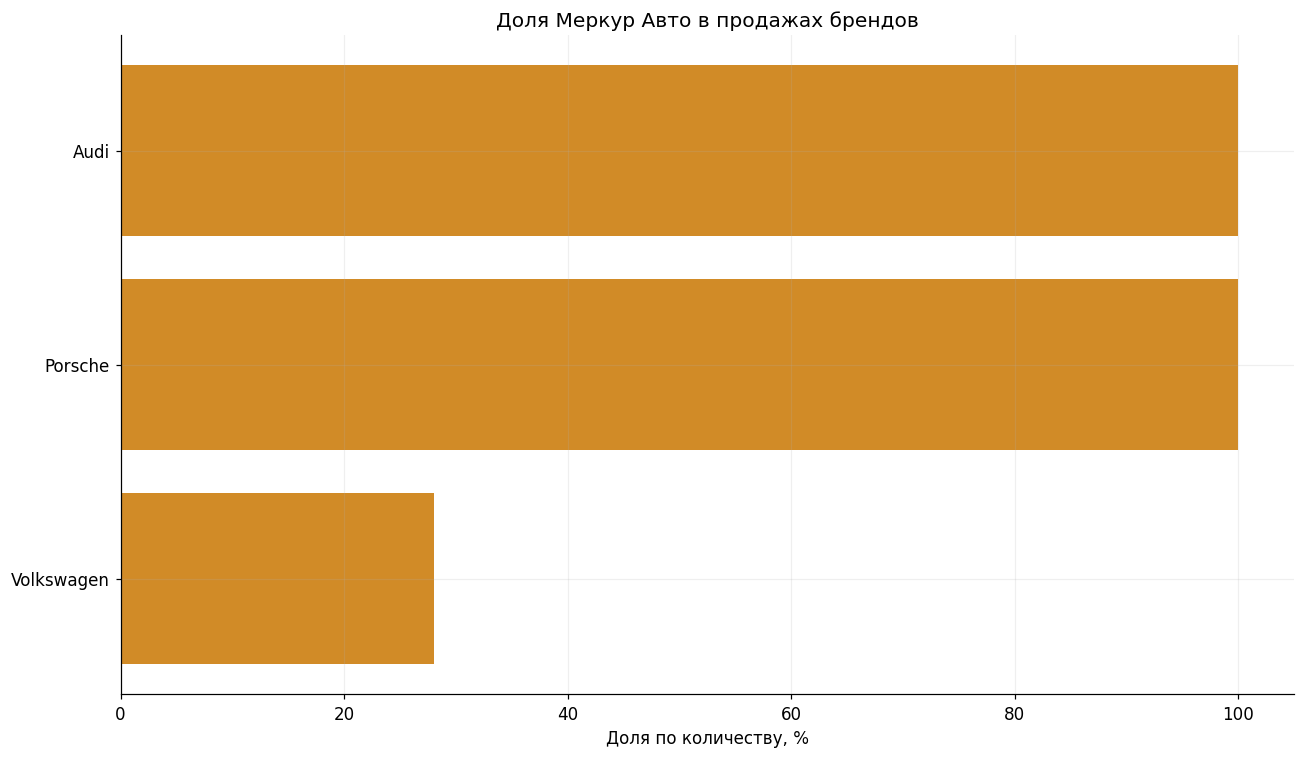

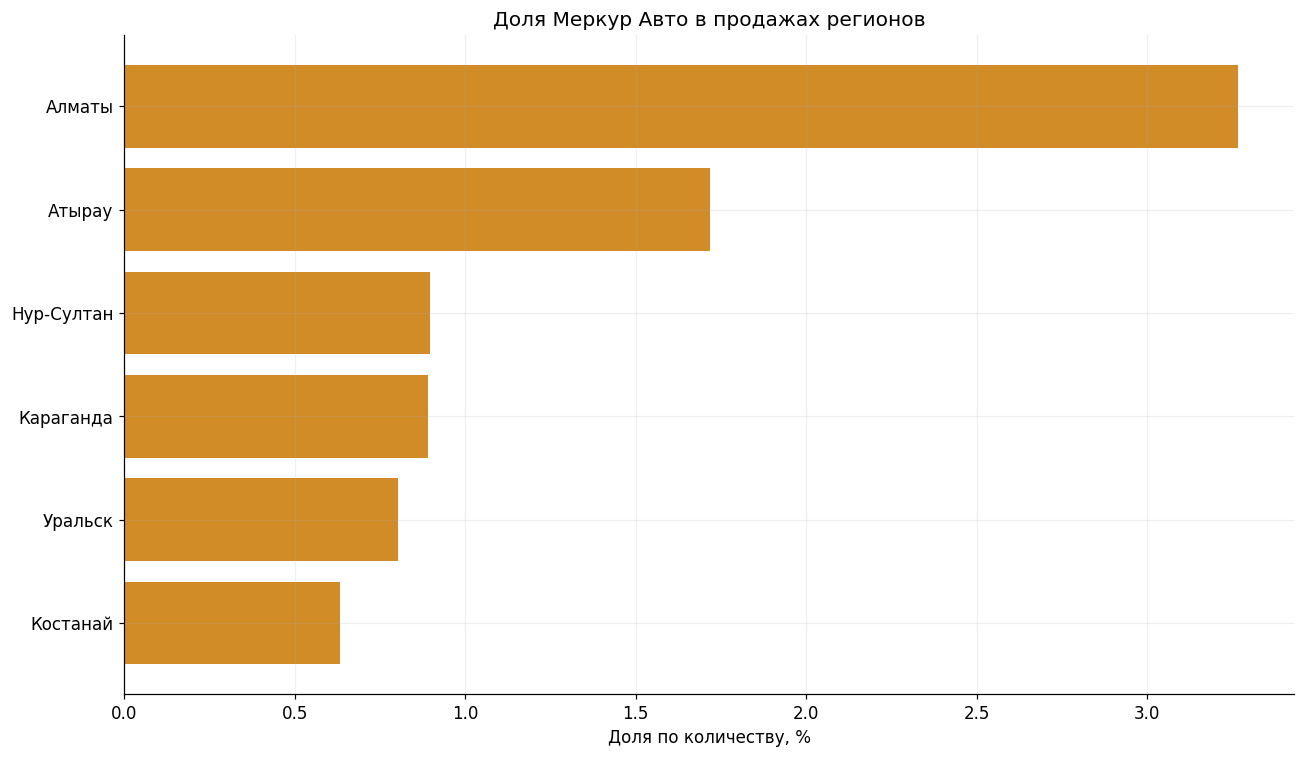

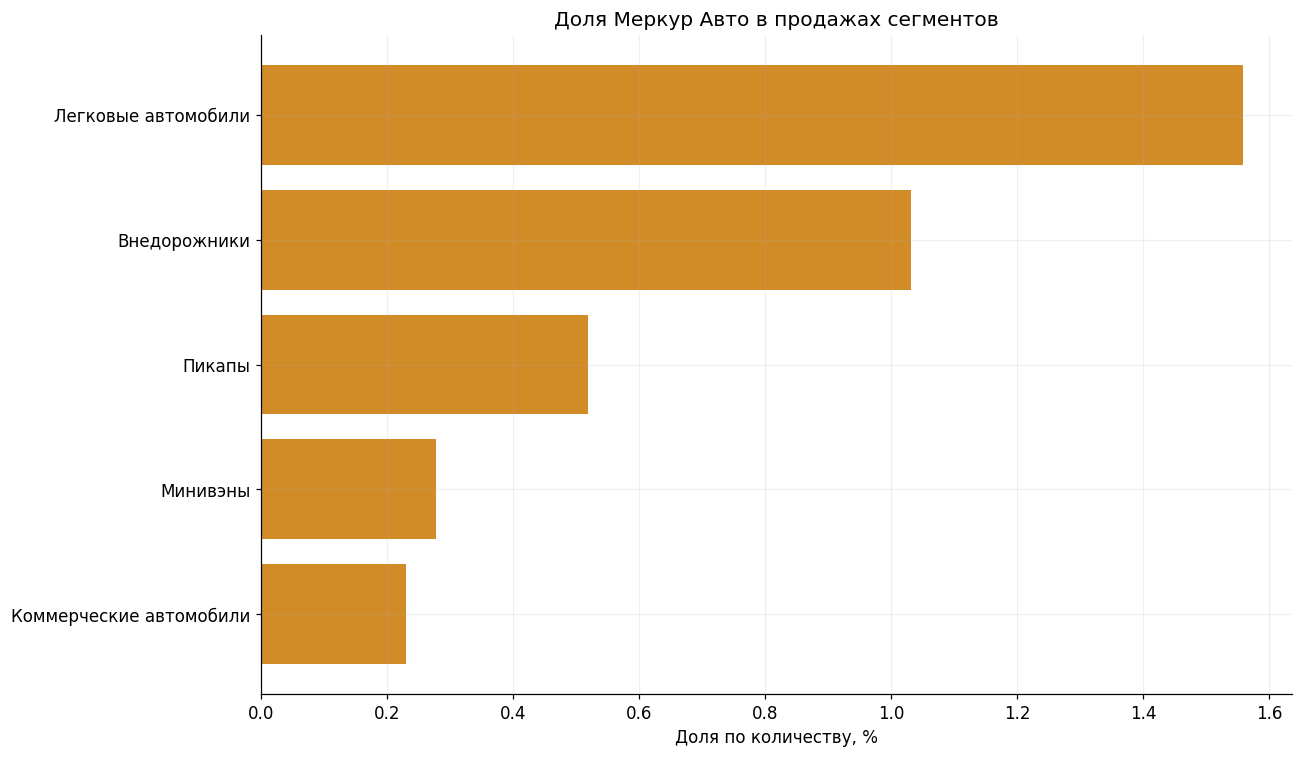

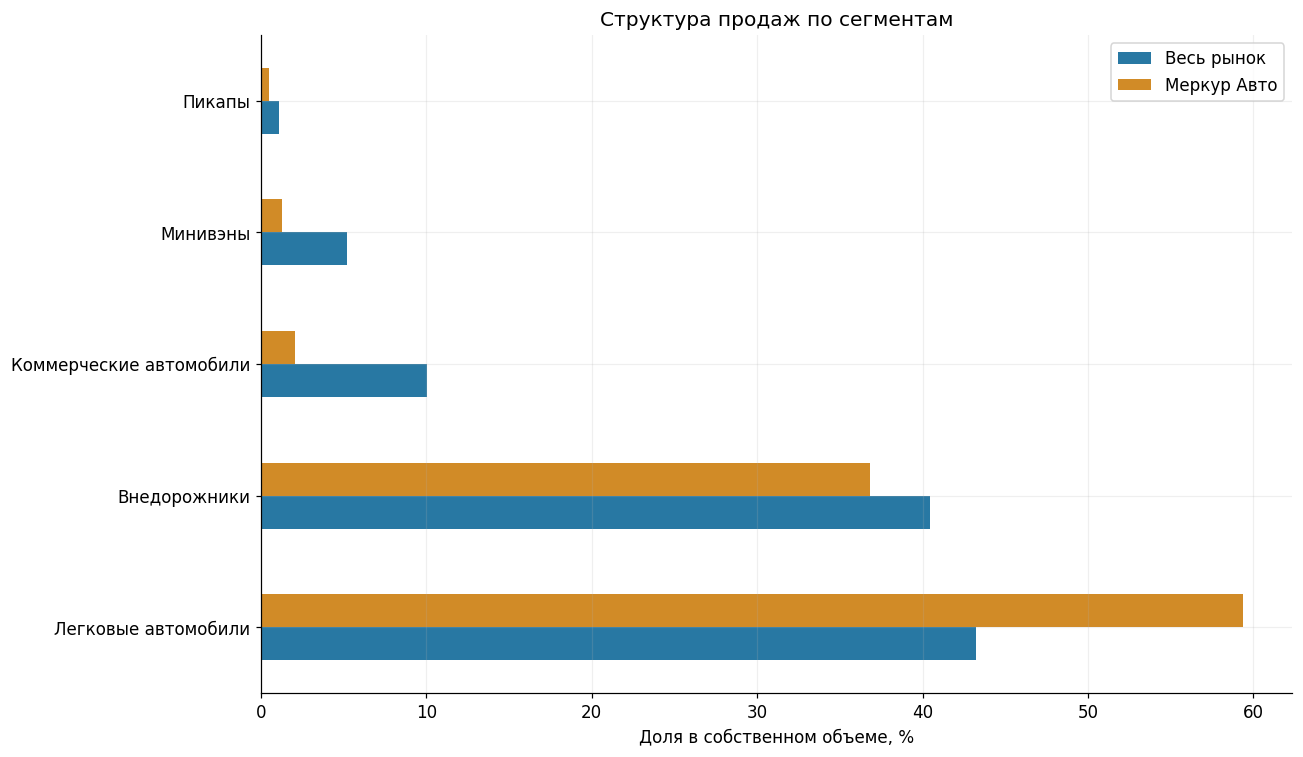

In [21]:
def compare_group(column):
    whole = market.groupby(column, observed=True).agg(
        market_units=('quantity', 'sum'), market_revenue=('total_price_usd', 'sum'))
    company = mercur.groupby(column, observed=True).agg(
        mercur_units=('quantity', 'sum'), mercur_revenue=('total_price_usd', 'sum'))
    comparison = whole.join(company).fillna(0)
    comparison['market_share_pct'] = comparison['mercur_units'] / comparison['market_units'] * 100
    comparison['market_mix_pct'] = comparison['market_units'] / market['quantity'].sum() * 100
    comparison['mercur_mix_pct'] = comparison['mercur_units'] / mercur['quantity'].sum() * 100
    comparison['market_avg_price'] = comparison['market_revenue'] / comparison['market_units']
    comparison['mercur_avg_price'] = comparison['mercur_revenue'] / comparison['mercur_units'].replace(0, np.nan)
    return comparison.sort_values('mercur_units', ascending=False)

comparison_labels = {'market_units': 'Автомобилей на рынке', 'mercur_units': 'Автомобилей Меркур',
    'market_revenue': 'Стоимость рынка, USD', 'mercur_revenue': 'Стоимость Меркур, USD',
    'market_share_pct': 'Доля Меркур в группе, %', 'market_mix_pct': 'Группа в рынке, %',
    'mercur_mix_pct': 'Группа в Меркур, %', 'market_avg_price': 'Средняя цена рынка, USD',
    'mercur_avg_price': 'Средняя цена Меркур, USD'}
comparisons = {column: compare_group(column) for column in ['brand', 'region', 'segment_2013', 'class_2013']}
for column, title in [('brand', 'Бренды'), ('region', 'Регионы'),
                      ('segment_2013', 'Сегменты'), ('class_2013', 'Классы')]:
    print(title)
    display(comparisons[column].rename(columns=comparison_labels))

for column, title in [('brand', 'Доля Меркур Авто в продажах брендов'),
                      ('region', 'Доля Меркур Авто в продажах регионов'),
                      ('segment_2013', 'Доля Меркур Авто в продажах сегментов')]:
    plotted = comparisons[column].loc[lambda table: table['mercur_units'].gt(0)].sort_values('market_share_pct')
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.barh(plotted.index.astype(str), plotted['market_share_pct'], color='#d18b27')
    ax.set(title=title, xlabel='Доля по количеству, %', ylabel='')
    fig.tight_layout()
    plt.show()

mix = comparisons['segment_2013'][['market_mix_pct', 'mercur_mix_pct']].rename(
    columns={'market_mix_pct': 'Весь рынок', 'mercur_mix_pct': 'Меркур Авто'})
fig, ax = plt.subplots(figsize=(12, 7))
mix.plot.barh(ax=ax, color=['#2878a3', '#d18b27'])
ax.set(title='Структура продаж по сегментам', xlabel='Доля в собственном объеме, %', ylabel='')
fig.tight_layout()
plt.show()

Основу продаж компании составляет Volkswagen — **294 автомобиля, 74,62%** ее объема.
Доля «Меркур Авто» внутри Volkswagen — **28,05%**. Audi — 48 автомобилей, Porsche — 52;
в очищенной выгрузке все продажи этих двух брендов отнесены к «Меркур Авто».
Это характеристика файла, а не доказательство монополии на реальном рынке.

Алматы дает **251 автомобиль, 63,71%** объема компании. Доля «Меркур Авто» в этом городе — 3,27%.
В Нур-Султане у компании 51 автомобиль и 0,90% местного рынка. Продажи по полю компании
представлены в шести регионах, то есть география заметно уже всей выборки.

Легковые автомобили составляют 59,39% продаж компании против 43,22% рынка.
Внедорожники — 36,80% против 40,45%. Коммерческий транспорт представлен только восемью автомобилями.
Доля компании в F-классе — 28,89%, но это 13 из 45 автомобилей; крупная доля маленькой группы
не означает крупного вклада в общий объем.

### 4.3. Сопоставимость средней цены

Для отделения влияния брендов сравниваем средние цены внутри бренда. Дополнительно рассчитываем
среднюю цену рынка при весах брендов «Меркур Авто»: это сумма рыночной средней цены бренда,
умноженной на его долю в продажах компании. Так обе стороны получают одинаковые веса брендов.
Модели и комплектации внутри брендов все еще могут различаться.

,Автомобилей на рынке,Автомобилей Меркур,"Средняя цена рынка, USD","Средняя цена Меркур, USD","Группа в Меркур, %"
brand,,,,,
Volkswagen,1048,294,20 662.22,21 425.84,74.62
Porsche,52,52,98 336.78,98 336.78,13.20
Audi,48,48,77 267.09,77 267.09,12.18


Рыночная средняя при структуре брендов Меркур, USD: 37809.71
Средняя Меркур, USD: 38379.52
Разница после учета структуры брендов, %: 1.51
Средняя Volkswagen у остальных компаний, USD: 20364.48


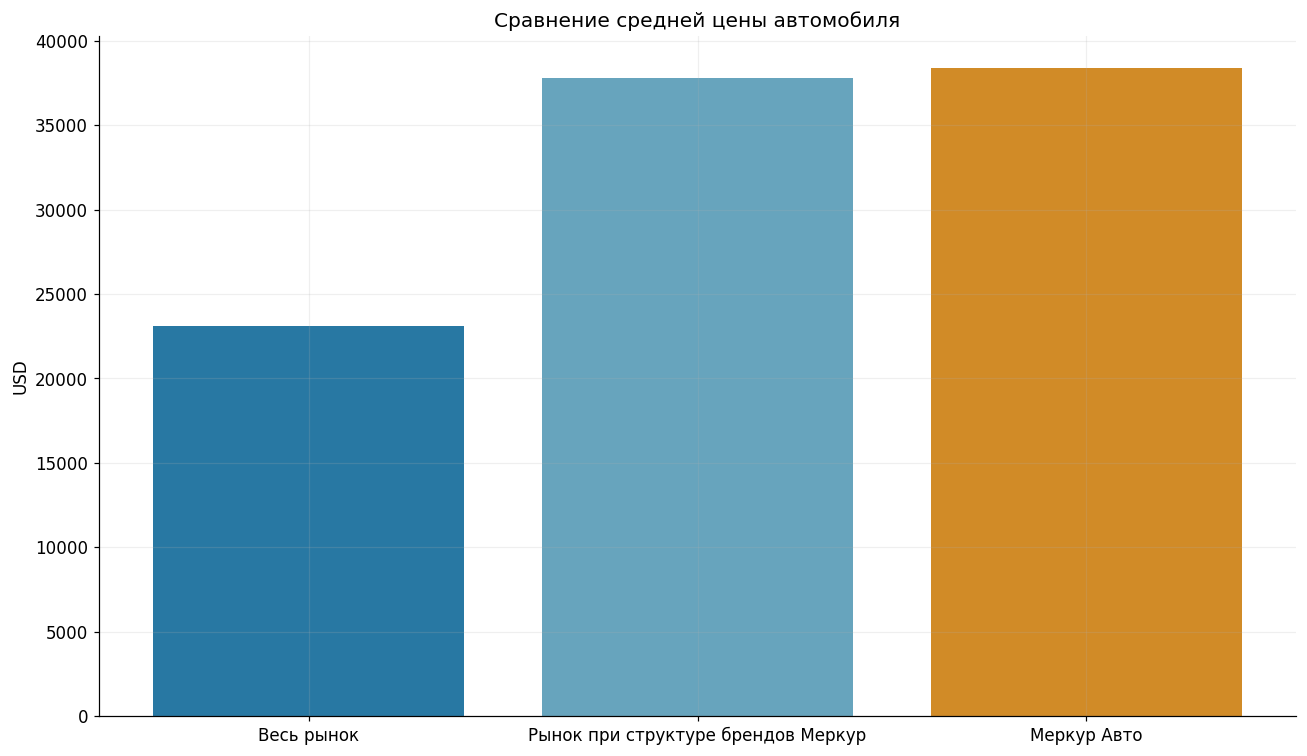

In [22]:
brand_comparison = comparisons['brand'].loc[lambda table: table['mercur_units'].gt(0)].copy()
show_columns = ['market_units', 'mercur_units', 'market_avg_price', 'mercur_avg_price', 'mercur_mix_pct']
display(brand_comparison[show_columns].rename(columns=comparison_labels))
standardized_market_price = (brand_comparison['market_avg_price'] * brand_comparison['mercur_mix_pct'] / 100).sum()
actual_mercur_price = mercur['total_price_usd'].sum() / mercur['quantity'].sum()
print('Рыночная средняя при структуре брендов Меркур, USD:', round(standardized_market_price, 2))
print('Средняя Меркур, USD:', round(actual_mercur_price, 2))
print('Разница после учета структуры брендов, %:', round((actual_mercur_price / standardized_market_price - 1) * 100, 2))
vw = market.loc[market['brand'].eq('Volkswagen')]
vw_other = vw.loc[~vw['company'].eq('Меркур Авто')]
print('Средняя Volkswagen у остальных компаний, USD:', round(vw_other['total_price_usd'].sum() / vw_other['quantity'].sum(), 2))
fig, ax = plt.subplots(figsize=(12, 7))
ax.bar(['Весь рынок', 'Рынок при структуре брендов Меркур', 'Меркур Авто'],
       [market['total_price_usd'].sum() / market['quantity'].sum(), standardized_market_price, actual_mercur_price],
       color=['#2878a3', '#67a4bd', '#d18b27'])
ax.set(title='Сравнение средней цены автомобиля', ylabel='USD')
fig.tight_layout()
plt.show()

При структуре брендов «Меркур Авто» рыночная средняя равна **37 809,71 USD**,
и превышение цены компании сокращается до **1,51%**. Большая часть исходной разницы с рынком
связана с составом брендов. Внутри Volkswagen средняя цена компании — 21 425,84 USD,
а остальных компаний — 20 364,48 USD. Это сравнение все еще зависит от моделей и комплектаций;
по Audi и Porsche в этой выборке нет других компаний для независимого сравнения.

### 4.4. Динамика и неоднозначность названия компании

В исходном файле есть два отдельных столбца: «Компания» и «Наименование дилерского центра».
Они могут содержать разные названия в одной строке продажи. Например, у части продаж Volkswagen
указаны такие сочетания:

| Компания | Наименование дилерского центра |
|---|---|
| Volkswagen Group Rus | Mercur Auto Алматы |
| Volkswagen Group Rus | Mercur Auto Атырау |
| Volkswagen Group Rus | Mercur Auto Астана |

С июня Volkswagen больше не встречается в строках с компанией «Меркур Авто», но в таблице
остаются продажи у дилеров Mercur Auto, записанные под компанией Volkswagen Group Rus.
Если отбирать только строки, где компания — «Меркур Авто», эти продажи не попадут в расчет,
хотя название дилерского центра по-прежнему содержит Mercur Auto. Поэтому снижение показателя
по полю компании может создавать неверное впечатление о снижении продаж самого автоцентра.
Почему изменилось заполнение поля «Компания», данные не объясняют.

Сначала проверяем сочетания названий в исходных полях, затем сравниваем продажи по компании
и по имени дилера. Третья линия показывает общий отбор: компания — «Меркур Авто» **или**
в имени дилера есть Mercur Auto. Для этого используем условие ИЛИ (`|`), которое включает
каждую подходящую строку только один раз.

Просто складывать первые две линии нельзя: часть записей подходит под оба условия.
Общий объем равен сумме двух отборов за вычетом их пересечения. Объединяем именно строки
по двум признакам; принадлежность всех этих дилерских центров одной организации в файле не установлена.

,Автомобилей,"Стоимость, USD","Доля рынка, %","Средняя цена, USD"
sale_date,,,,
2019-01-31,58,1 430 299.93,1.96,24 660.34
2019-02-28,93,2 415 248.12,2.91,25 970.41
2019-03-31,62,2 383 403.86,1.80,38 442.00
2019-04-30,68,2 414 052.74,1.59,35 500.78
2019-05-31,66,2 351 547.35,1.55,35 629.51
2019-06-30,8,756 811.00,0.19,94 601.38
2019-07-31,16,1 307 886.00,0.36,81 742.88
2019-08-31,13,1 031 434.04,0.31,79 341.08
2019-09-30,10,1 030 846.00,0.27,103 084.60


brand,Audi,Porsche,Volkswagen
sale_date,,,
2019-01-31,2,1,55
2019-02-28,2,5,86
2019-03-31,9,7,46
2019-04-30,4,8,56
2019-05-31,7,8,51
2019-06-30,3,5,0
2019-07-31,9,7,0
2019-08-31,6,7,0
2019-09-30,6,4,0


,Компания,Бренд,Наименование дилерского центра
0,Mercur Auto,Audi,Mercur Auto Алматы
5,Mercur Auto,Audi,Mercur Auto Астана
37850,Volkswagen Group Rus,Volkswagen,Mercur Auto Атырау
37851,Volkswagen Group Rus,Volkswagen,Mercur Auto Алматы
37866,Volkswagen Group Rus,Volkswagen,Mercur Auto Астана
37875,Mercur Auto,Volkswagen,Mercur Auto Астана
37877,Mercur Auto,Volkswagen,Mercur Auto Атырау
37879,Mercur Auto,Volkswagen,Mercur Auto Алматы


,По полю компании,По имени дилера Mercur Auto,Общий отбор без повторного учета
Строк,387.00,334.00,434.00
Автомобилей с учетом возвратов,394.00,712.00,813.00
"Стоимость продаж, USD",15 121 529.04,16 772 733.42,23 115 025.21
"Средняя цена автомобиля, USD",38 379.52,23 557.21,28 431.77
"Доля по количеству, %",1.13,2.05,2.34
"Доля по стоимости, %",1.89,2.09,2.88


,По полю компании,По имени дилера Mercur Auto,Общий отбор без повторного учета
Месяц,,,
2019-01-31,58,55,58
2019-02-28,93,61,93
2019-03-31,62,38,62
2019-04-30,68,61,71
2019-05-31,66,80,89
2019-06-30,8,118,123
2019-07-31,16,50,57
2019-08-31,13,125,132
2019-09-30,10,124,128


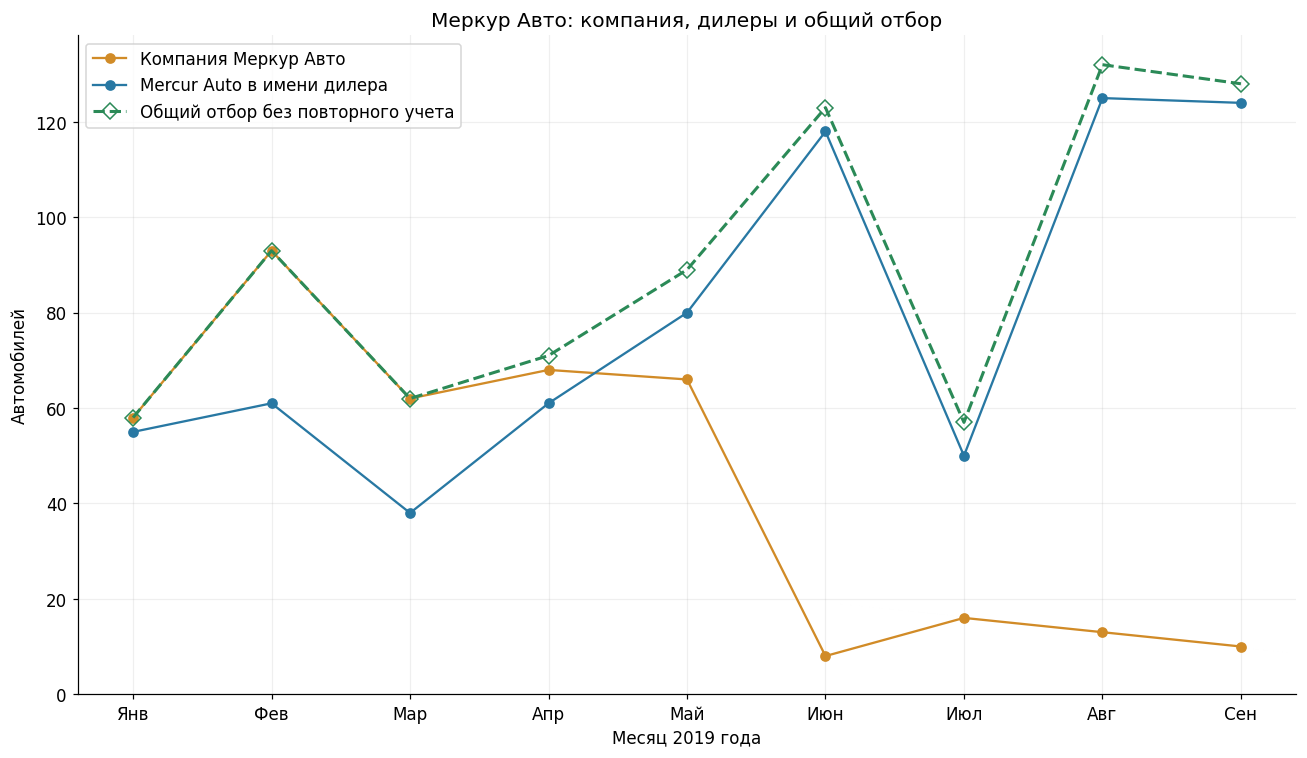

In [23]:
mercur_monthly = mercur.groupby('sale_date').agg(units=('quantity', 'sum'), revenue=('total_price_usd', 'sum'))
mercur_monthly['market_share_pct'] = mercur_monthly['units'] / monthly['units'] * 100
mercur_monthly['avg_price'] = mercur_monthly['revenue'] / mercur_monthly['units']
display(mercur_monthly.rename(columns={'units': 'Автомобилей', 'revenue': 'Стоимость, USD',
    'market_share_pct': 'Доля рынка, %', 'avg_price': 'Средняя цена, USD'}))
display(mercur.pivot_table(index='sale_date', columns='brand', values='quantity', aggfunc='sum', fill_value=0))
source_evidence = raw_data.loc[
    raw_data['Наименование дилерского центра'].str.contains('mercur|меркур', case=False, na=False),
    ['Компания', 'Бренд', 'Наименование дилерского центра'],
].drop_duplicates()
display(source_evidence)
named_dealers = market.loc[market['is_mercur_dealer']]
# Условие ИЛИ включает каждую подходящую строку только один раз
combined_mercur = market.loc[market['company'].eq('Меркур Авто') | market['is_mercur_dealer']]
display(pd.DataFrame({
    'По полю компании': kpi(mercur),
    'По имени дилера Mercur Auto': kpi(named_dealers),
    'Общий отбор без повторного учета': kpi(combined_mercur),
}))
named_monthly = named_dealers.groupby('sale_date')['quantity'].sum().reindex(monthly.index, fill_value=0)
combined_monthly = combined_mercur.groupby('sale_date')['quantity'].sum().reindex(monthly.index, fill_value=0)
selection_monthly = pd.DataFrame({
    'По полю компании': mercur_monthly['units'].reindex(monthly.index, fill_value=0),
    'По имени дилера Mercur Auto': named_monthly,
    'Общий отбор без повторного учета': combined_monthly,
})
display(selection_monthly.rename_axis('Месяц'))
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(month_labels, selection_monthly['По полю компании'], marker='o', color='#d18b27', label='Компания Меркур Авто')
ax.plot(month_labels, named_monthly, marker='o', color='#2878a3', label='Mercur Auto в имени дилера')
ax.plot(month_labels, combined_monthly, marker='D', markerfacecolor='none', markersize=7,
        linestyle='--', linewidth=2, color='#2b8a57', label='Общий отбор без повторного учета')
ax.set(title='Меркур Авто: компания, дилеры и общий отбор', xlabel='Месяц 2019 года', ylabel='Автомобилей')
ax.set_ylim(bottom=0)
ax.legend()
fig.tight_layout()
plt.show()

По компании объем падает с 66 автомобилей в мае до 8 в июне, а средняя цена увеличивается:
в составе остаются Audi и Porsche. По имени дилера Mercur Auto в июне учтено **118 автомобилей**.
За девять месяцев второй способ отбора дает **712 автомобилей**, 2,05% рынка и среднюю цену
23 557,21 USD. У 419 из них компания записана как Volkswagen Group Rus.

Компания «Меркур Авто» также включает 101 автомобиль у дилеров с другими названиями,
в том числе Porsche Centre Almaty. Поэтому второй срез не является полной заменой первого.
Данные показывают различие способов учета; устойчивое падение реальных продаж автоцентра
по одной серии компании подтвердить нельзя.

В общем отборе **813 автомобилей**, или **2,34%** внутреннего рынка. Из них 293 автомобиля
попадают одновременно в отбор по компании и по имени дилера, поэтому итог равен
**394 + 712 − 293 = 813**, а не 1 106. В июне общий объем составляет 123 автомобиля,
в августе — 132, в сентябре — 128. В январе — марте общий отбор совпадает с отбором по компании,
поэтому зеленая и оранжевая линии на этом участке накладываются друг на друга.
Это объединенный результат двух правил отбора в выгрузке, а не подтвержденная структура владения дилерами.

### 4.5. Чувствительность к удалению повторов

В основном сценарии полные повторы удалены по заданию. Но одинаковые месячные записи без VIN
и номера сделки могут означать разные продажи. Повторяем те же преобразования без удаления
полных совпадений и сравниваем ключевые показатели. Это альтернативный расчет, исходный и итоговый
CSV не перезаписываются.

In [24]:
def clean_data(raw, remove_duplicates=True):
    audit = []
    data = prepare_rows(raw, audit, remove_duplicates=remove_duplicates)
    data = normalize_categories(data, audit)
    data = clean_specs(data, audit)
    data = finalize_data(data, audit)
    validate_data(data)
    return data, pd.DataFrame(audit)

In [25]:
data_with_repeats, _ = clean_data(raw_data, remove_duplicates=False)
market_with_repeats = data_with_repeats.loc[~data_with_repeats['is_export'] & data_with_repeats['quantity'].notna()]

def scenario_kpi(frame):
    company = frame.loc[frame['company'].eq('Меркур Авто')]
    dealer = frame.loc[frame['is_mercur_dealer']]
    return pd.Series({
        'Объем рынка, автомобилей': frame['quantity'].sum(),
        'Стоимость рынка, USD': frame['total_price_usd'].sum(),
        'Средняя цена рынка, USD': frame['total_price_usd'].sum() / frame['quantity'].sum(),
        'Объем Меркур по компании': company['quantity'].sum(),
        'Доля Меркур по компании, %': company['quantity'].sum() / frame['quantity'].sum() * 100,
        'Объем по имени дилера': dealer['quantity'].sum(),
        'Доля по имени дилера, %': dealer['quantity'].sum() / frame['quantity'].sum() * 100,
    })

sensitivity = pd.DataFrame({'Повторы удалены': scenario_kpi(market),
                           'Повторы сохранены': scenario_kpi(market_with_repeats)})
display(sensitivity)
print('Три крупнейших бренда без удаления повторов')
show_sales_table(sales_summary(market_with_repeats, 'brand').head(3))

,Повторы удалены,Повторы сохранены
"Объем рынка, автомобилей",34 725.00,51 955.00
"Стоимость рынка, USD",801 697 865.97,1 311 276 915.61
"Средняя цена рынка, USD",23 087.05,25 238.70
Объем Меркур по компании,394.00,650.00
"Доля Меркур по компании, %",1.13,1.25
Объем по имени дилера,712.00,960.00
"Доля по имени дилера, %",2.05,1.85


Три крупнейших бренда без удаления повторов


,Строк,Автомобилей,"Стоимость, USD","Доля, %","Средняя цена, USD"
brand,,,,,
Lada,1967,11092,107 847 478.95,21.35,9 723.00
Toyota,10524,10524,392 717 580.72,20.26,37 316.38
Hyundai,10008,10008,226 131 593.82,19.26,22 595.08


Если считать все одинаковые исходные записи разными продажами, внутренний объем составляет
**51 955 автомобилей** вместо 34 725. Объем «Меркур Авто» по компании — 650 вместо 394,
а доля — **1,25% вместо 1,13%**. Средняя цена рынка — 25 238,70 USD вместо 23 087,05 USD.
Удаление повторов существенно влияет на абсолютные значения и неодинаково затрагивает компании.
Итоги основного сценария следует читать вместе с этим ограничением.

## 5. Общий вывод

В работе обработаны данные о продажах автомобилей в Казахстане за январь — сентябрь 2019 года.
Исходная выгрузка содержала 39 966 строк и 25 столбцов. После удаления 18 698 полных повторов
по условию задания осталось 21 268 строк. Таблица приведена к единым названиям полей и компаний,
страны закодированы трехбуквенными кодами, характеристики автомобилей нормализованы,
а месяцы продаж преобразованы в даты конца отчетного месяца. Дата не трактуется как точный день сделки.

При очистке восстановлены сдвинутые поля в 27 строках Renault, исправлены 25 ошибочных объемов
Chevrolet Niva и отделены мощность и емкость батареи от объема двигателя электрического транспорта.
Четыре модификации E-Hybrid отнесены к гибридам. Пропуски характеристик сохранены там,
где данные не позволяли надежно восстановить значение. Сохранены один возврат и крупные партии,
включая 100 Skoda Octavia и 115 Lada 4x4. Их количество согласуется с итоговой стоимостью.
Шесть строк с неизвестным количеством оставлены в CSV, но исключены из расчетов продаж.

После отделения 440 экспортированных автомобилей внутренний объем очищенной выборки равен
34 725 автомобилям с учетом возврата, а стоимость продаж — 801,70 млн USD. Средняя цена
автомобиля составляет 23 087,05 USD. Медианная цена положительных продаж — 16 000 USD,
поэтому распределение имеет заметный правый хвост. Большинство автомобилей с известным годом
выпуска произведены в 2019 или 2018 году. Медианный объем двигателя составляет 1,69 л.

По количеству в основном сценарии лидируют Lada, Hyundai и Toyota. Крупнейшая модель —
Lada Granta, 3 663 автомобиля. Toyota занимает первое место среди брендов по стоимости продаж.
Больше всего автомобилей учтено в Алматы и Нур-Султане: вместе эти города дают 38,49% внутреннего
объема. Основные сегменты — легковые автомобили и внедорожники; коммерческая техника также
входит в исследуемый рынок. Среди заполненных видов топлива преобладает бензин.
Максимальный месячный объем приходится на июль, минимальный — на январь.
Эти девять месяцев не позволяют установить устойчивую сезонность.

По нормализованному полю компании «Меркур Авто» учтено 394 автомобиля на 15,12 млн USD.
Доля составляет 1,13% количества и 1,89% стоимости. Средняя цена 38 379,52 USD выше рыночной,
но сравнение внутри брендов показывает существенную роль ассортимента. Volkswagen дает 74,62%
объема компании, а Алматы — 63,71%. В выборке «Меркур Авто» обеспечивает все продажи Audi и Porsche
и 28,05% продаж Volkswagen. Сильная сторона наблюдаемого положения — присутствие в дорогих
брендах и высокая доля стоимости относительно количества. Ограничения — небольшой общий объем,
концентрация на одном бренде и городе и слабое присутствие в коммерческом сегменте.
Это характеристики структуры продаж; прибыльность и качество управления по выгрузке не определяются.

Динамику компании ограничивает неоднозначный учет. В исходном файле «Компания» и
«Наименование дилерского центра» — разные поля. С июня продажи Volkswagen встречаются
у дилеров Mercur Auto, но в поле «Компания» указано Volkswagen Group Rus. Такие записи
не попадают в отбор по компании «Меркур Авто», хотя имя дилера остается Mercur Auto.
Поэтому резкое снижение показателя компании не доказывает падения реальных продаж автоцентра.
Причину изменения заполнения поля по этим данным установить нельзя. Отбор по имени дилера
дает 712 автомобилей и долю 2,05%, но не включает часть других дилерских названий из среза компании.
Объединение двух отборов без повторного учета общих строк дает 813 автомобилей и долю 2,34%.
Этот показатель относится к объединению записей по двум полям; принадлежность всех дилеров
одной организации по нему не устанавливается.

Без удаления полных совпадений объем внутреннего рынка равен 51 955 автомобилям,
а доля компании — 1,25%. Отсутствие идентификаторов сделок не позволяет окончательно различить
дубли выгрузки и одинаковые продажи. Полученные результаты относятся к явно заданному сценарию обработки.

## 6. Итоговый CSV

Файл `autokz2019_clean.csv` содержит все очищенные записи, включая экспорт, возврат и строки
с частично неизвестными характеристиками. Ограничения аналитических срезов не удаляют эти данные.
Для внутреннего рынка используйте `is_export = False` и заполненное `quantity`.
Для распределений проданных автомобилей дополнительно задайте `quantity > 0`.

| Поля | Смысл и формат |
|---|---|
| `source_row` | Номер строки в исходном CSV с учетом заголовка, для проверки происхождения записи |
| `company`, `brand`, `model` | Нормализованные компания, бренд и модель |
| `production_year` | Год выпуска, целое число или пропуск |
| `country` | Страна производства, ALPHA-3 |
| `fuel_type` | F, D, E, HYB или пропуск |
| `engine_volume_l` | Объем ДВС в литрах; 0 у электрического транспорта, пропуск при неизвестном объеме |
| `transmission`, `drive_type` | Автомат / Механика; FWD / RWD / 4WD / 2WD; неизвестные значения пустые |
| `region`, `area` | Географические названия из исходной выгрузки в едином регистре |
| `quantity` | Число автомобилей, отрицательное при возврате; шесть значений неизвестны |
| `unit_price_usd`, `total_price_usd` | Цена одного автомобиля и стоимость строки в USD |
| `segment_2013`, `class_2013` | Сегмент и класс из классификации 2013 года |
| `sale_date` | Дата конца месяца в формате YYYY-MM-DD |
| `is_return`, `is_export`, `is_batch`, `is_mercur_dealer` | Логические признаки для отбора записей |

Формат выгрузки: **UTF-8 с BOM, разделитель — запятая, десятичный знак — точка**, индекс pandas не записывается.
Пропуски представлены пустыми полями. CSV не хранит типы `category` и `datetime`, поэтому при повторной
загрузке явно восстанавливаем их и проверяем совпадение данных. Выгрузка проходит проверку числа строк,
пропусков, сумм и содержимого каждого столбца.

In [26]:
output_path = Path('autokz2019_clean.csv')
validate_data(data)
data.to_csv(output_path, index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')

# Повторное чтение проверяет именно записанный файл
string_columns = ['company', 'brand', 'model', 'country', 'region', 'area'] + CATEGORY_COLUMNS
loaded = pd.read_csv(output_path, encoding='utf-8-sig', dtype={column: 'string' for column in string_columns},
                     parse_dates=['sale_date'])
for column in data.columns:
    loaded[column] = loaded[column].astype(data[column].dtype)
pd.testing.assert_frame_equal(data, loaded, check_exact=False, rtol=1e-12, atol=1e-7)
display(validate_data(loaded))
print(f'Сохранено: {output_path.resolve()}')
print(f'Строк: {len(loaded)}, столбцов: {len(loaded.columns)}')
print('Повторное чтение: значения, пропуски и восстановленные типы совпадают')

,Проверка,Пройдена
0,Уникальны ссылки на исходные строки,True
1,Цена автомобиля положительна,True
2,Количество согласуется с итоговой стоимостью,True
3,Даты заполнены и относятся к концу месяца,True
4,Год выпуска не позже года продажи,True
5,Страны заданы кодами ALPHA-3,True
6,Топливо содержит только допустимые категории,True
7,Коробки сведены к двум категориям,True
8,Привод содержит только допустимые категории,True
9,Нулевой объем есть только у электромобилей,True


Сохранено: /Users/ilya/Desktop/Data Preprocessing and Analysis/autokz2019_clean.csv
Строк: 21268, столбцов: 22
Повторное чтение: значения, пропуски и восстановленные типы совпадают
